In [ ]:
import os
import zipfile
from pathlib import Path

# ============================================================
# STEP 1: EXTRACT AND VERIFY THE FOUR DATASET PACKAGES
# ============================================================

base_dir = Path("/content/cross_dataset")
base_dir.mkdir(parents=True, exist_ok=True)

expected_zips = [
    "NLR_processed_and_metadata.zip",
    "NORCE_processed_and_metadata.zip",
    "METEOSAT_processed_and_metadata.zip",
    "PVDAQ_processed_and_metadata.zip"
]

# Search common Colab upload locations
search_dirs = [Path("/content"), Path("/content/drive/MyDrive")]

found_zips = {}

for zip_name in expected_zips:
    for search_dir in search_dirs:
        candidate = search_dir / zip_name
        if candidate.exists():
            found_zips[zip_name] = candidate
            break

print("=" * 70)
print("DATASET PACKAGE EXTRACTION")
print("=" * 70)

missing_zips = []

for zip_name in expected_zips:

    if zip_name not in found_zips:
        print(f"\nNOT FOUND: {zip_name}")
        missing_zips.append(zip_name)
        continue

    zip_path = found_zips[zip_name]
    folder_name = zip_name.replace("_processed_and_metadata.zip", "").lower()
    extract_dir = base_dir / folder_name
    extract_dir.mkdir(parents=True, exist_ok=True)

    with zipfile.ZipFile(zip_path, "r") as archive:
        archive.extractall(extract_dir)

    print(f"\nEXTRACTED: {zip_name}")
    print(f"LOCATION: {extract_dir}")

    extracted_files = [
        file for file in extract_dir.rglob("*") if file.is_file()
    ]

    for file in extracted_files:
        size_kb = file.stat().st_size / 1024
        print(f"  {file.relative_to(extract_dir)} | {size_kb:.2f} KB")

    print(f"Total files: {len(extracted_files)}")

print("\n" + "=" * 70)

if missing_zips:
    print("INCOMPLETE: The following ZIP files were not found:")
    for name in missing_zips:
        print(" -", name)
else:
    print("SUCCESS: All four ZIP packages were extracted.")

print("Extraction directory:", base_dir)

DATASET PACKAGE EXTRACTION

EXTRACTED: NLR_processed_and_metadata.zip
LOCATION: /content/cross_dataset/nlr
  metadata/nlr_feature_roles.csv | 4.09 KB
  processed/nlr_observation_clean.csv | 22967.46 KB
  processed/nlr_minute_candidate.csv | 1326.15 KB
Total files: 3

EXTRACTED: NORCE_processed_and_metadata.zip
LOCATION: /content/cross_dataset/norce
  NORCE_processed_and_metadata/metadata/norce_eda_decisions.txt | 1.89 KB
  NORCE_processed_and_metadata/metadata/norce_feature_roles.csv | 0.78 KB
  NORCE_processed_and_metadata/metadata/norce_data_quality_report.csv | 0.28 KB
  NORCE_processed_and_metadata/processed/norce_test2_processed.csv | 1766.59 KB
  NORCE_processed_and_metadata/processed/norce_test4_processed.csv | 9018.25 KB
  NORCE_processed_and_metadata/processed/norce_test3_processed.csv | 1658.04 KB
Total files: 6

EXTRACTED: METEOSAT_processed_and_metadata.zip
LOCATION: /content/cross_dataset/meteosat
  metadata/meteosat_visual_eda_findings.txt | 1.92 KB
  metadata/meteosat_fe

In [ ]:
import pandas as pd
from pathlib import Path

# ============================================================
# STEP 2: LOAD ALL PROCESSED DATASETS
# ============================================================

base_dir = Path("/content/cross_dataset")

# Locate files recursively to handle nested ZIP folders
def locate_csv(dataset_folder, filename):
    matches = list((base_dir / dataset_folder).rglob(filename))

    if len(matches) != 1:
        raise FileNotFoundError(
            f"Expected exactly one {filename} in {dataset_folder}, "
            f"but found {len(matches)}"
        )

    return matches[0]


# NLR
df_nlr_observation = pd.read_csv(
    locate_csv("nlr", "nlr_observation_clean.csv")
)

df_nlr_minute = pd.read_csv(
    locate_csv("nlr", "nlr_minute_candidate.csv")
)

# NORCE
df_norce_test2 = pd.read_csv(
    locate_csv("norce", "norce_test2_processed.csv")
)

df_norce_test3 = pd.read_csv(
    locate_csv("norce", "norce_test3_processed.csv")
)

df_norce_test4 = pd.read_csv(
    locate_csv("norce", "norce_test4_processed.csv")
)

# METEOSAT
df_meteosat = pd.read_csv(
    locate_csv("meteosat", "meteosat_observation_clean.csv")
)

# PVDAQ
df_pvdaq = pd.read_csv(
    locate_csv("pvdaq", "pvdaq_system_catalogue_processed.csv")
)


# Register all loaded dataframes
loaded_datasets = {
    "NLR Observation": df_nlr_observation,
    "NLR Minute": df_nlr_minute,
    "NORCE TEST2": df_norce_test2,
    "NORCE TEST3": df_norce_test3,
    "NORCE TEST4": df_norce_test4,
    "METEOSAT": df_meteosat,
    "PVDAQ Catalogue": df_pvdaq
}


# Print verification
print("=" * 75)
print("PROCESSED DATASET LOADING REPORT")
print("=" * 75)

for name, frame in loaded_datasets.items():
    print(f"\n{name}")
    print(f"Shape: {frame.shape}")
    print(f"Columns ({len(frame.columns)}):")
    print(list(frame.columns))

print("\n" + "=" * 75)
print("ALL SEVEN PROCESSED DATAFRAMES LOADED SUCCESSFULLY")
print("=" * 75)

PROCESSED DATASET LOADING REPORT

NLR Observation
Shape: (61081, 44)
Columns (44):
['Unnamed: 0', 'Wind Turbine Power (kW)', 'H2E_f_NLR_CurrentCmd (A)', 'IVAL_f_FM011_Flow', 'Efficiency (kWh/kg)', 'Power Supply Average Voltage (Vdc)', 'H2E_f_NLR_CurrentCmd', 'H2E_n_PSU_A_Power', 'H2E_f_PSU_A_Current', 'H2E_f_Elec_CalcProdRate', 'H2E_f_CG220_LFLPer', 'H2E_f_DPS340_DPdegC', 'H2E_f_DPS341_DPdegC', 'H2E_f_DPS341_DPppmV', 'H2E_f_LS201_H2OLevel', 'H2E_f_LS301_H2OLevel', 'H2E_f_PT264_Pressure', 'H2E_f_PT307_Pressure', 'H2E_f_PT312_Pressure', 'H2E_f_PT604_Pressure', 'H2E_f_RS209_Resistivity', 'H2E_f_RS507_Resistivity', 'H2E_f_TE218_Temp', 'H2E_f_TE219_Temp', 'H2E_f_TE338_Temp', 'H2E_f_TE601_Temp', 'H2E_f_TT641_Temp', 'H2E_f_TT645_Temp', 'H2E_f_TT646_Temp', 'H2E_f_TT647_Temp', 'Experiment', 'Unnamed: 31', 'Flow_Was_Interpolated', 'Original_Row_Index', 'Parsed_Timestamp', 'Calculated_PSU_Power_W', 'Power_Difference_W', 'Power_Relative_Error_Percent', 'Calculated_PSU_Power_kW', 'Power_Difference_

In [ ]:
# ============================================================
# STEP 3: CROSS-DATASET VARIABLE INVENTORY
# ============================================================

inventory_frames = {
    "NLR_Observation": df_nlr_observation,
    "NLR_Minute": df_nlr_minute,
    "NORCE_TEST2": df_norce_test2,
    "NORCE_TEST3": df_norce_test3,
    "NORCE_TEST4": df_norce_test4,
    "METEOSAT": df_meteosat,
    "PVDAQ_Catalogue": df_pvdaq
}

inventory_records = []

for dataset_name, frame in inventory_frames.items():

    for column in frame.columns:

        inventory_records.append({
            "Dataset": dataset_name,
            "Variable": column,
            "Data_Type": str(frame[column].dtype),
            "Missing_Count": int(frame[column].isna().sum()),
            "Missing_Percentage": round(
                frame[column].isna().mean() * 100, 3
            ),
            "Unique_Values": int(frame[column].nunique(dropna=True))
        })

df_cross_inventory = pd.DataFrame(inventory_records)

# Dataset-level summary
print("=" * 75)
print("DATASET VARIABLE SUMMARY")
print("=" * 75)

summary = (
    df_cross_inventory
    .groupby("Dataset")
    .agg(
        Total_Variables=("Variable", "count"),
        Numeric_Variables=("Data_Type", lambda x: sum(
            dtype in ["int64", "float64", "int32", "float32"]
            for dtype in x
        )),
        Variables_With_Missing=("Missing_Count", lambda x: sum(x > 0))
    )
)

display(summary)

# Full variable inventory
print("\nCOMPLETE VARIABLE INVENTORY")
display(df_cross_inventory)

# Important candidate physical variables
print("\nKEY PHYSICAL AND OPERATIONAL VARIABLES")

keywords = [
    "flow", "hydrogen", "current", "voltage", "power",
    "pressure", "temp", "wind", "solar", "ghi",
    "dni", "dhi", "humidity", "irradiance", "cv-mean"
]

key_variables = df_cross_inventory[
    df_cross_inventory["Variable"].str.lower().apply(
        lambda name: any(word in name for word in keywords)
    )
]

display(key_variables)

DATASET VARIABLE SUMMARY


,Total_Variables,Numeric_Variables,Variables_With_Missing
Dataset,,,
METEOSAT,14,13,0
NLR_Minute,115,111,11
NLR_Observation,44,38,4
NORCE_TEST2,6,6,5
NORCE_TEST3,6,6,5
NORCE_TEST4,6,6,0
PVDAQ_Catalogue,36,17,15



COMPLETE VARIABLE INVENTORY


,Dataset,Variable,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
0,NLR_Observation,Unnamed: 0,object,0,0.000,1034
1,NLR_Observation,Wind Turbine Power (kW),float64,17828,29.187,17503
2,NLR_Observation,H2E_f_NLR_CurrentCmd (A),float64,0,0.000,34439
3,NLR_Observation,IVAL_f_FM011_Flow,float64,0,0.000,19725
4,NLR_Observation,Efficiency (kWh/kg),float64,1,0.002,53242
...,...,...,...,...,...,...
222,PVDAQ_Catalogue,Adequate_Coverage,bool,0,0.000,2
223,PVDAQ_Catalogue,Known_Capacity,bool,0,0.000,2
224,PVDAQ_Catalogue,Unique_System_ID,bool,0,0.000,2
225,PVDAQ_Catalogue,QA_Pass,bool,0,0.000,2



KEY PHYSICAL AND OPERATIONAL VARIABLES


,Dataset,Variable,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
1,NLR_Observation,Wind Turbine Power (kW),float64,17828,29.187,17503
2,NLR_Observation,H2E_f_NLR_CurrentCmd (A),float64,0,0.000,34439
3,NLR_Observation,IVAL_f_FM011_Flow,float64,0,0.000,19725
5,NLR_Observation,Power Supply Average Voltage (Vdc),float64,0,0.000,2090
6,NLR_Observation,H2E_f_NLR_CurrentCmd,float64,0,0.000,28532
...,...,...,...,...,...,...
187,METEOSAT,Relative Humidity,float64,0,0.000,8394
188,METEOSAT,Pressure,int64,0,0.000,16
189,METEOSAT,Solar Zenith Angle,float64,0,0.000,14651
204,PVDAQ_Catalogue,pvcz_humidity,int64,0,0.000,4


In [ ]:

# ============================================================
# STEP 4: COMPLETE TEMPORAL COMPATIBILITY ASSESSMENT
# ============================================================

import pandas as pd

print("=" * 75)
print("TEMPORAL COMPATIBILITY ASSESSMENT")
print("=" * 75)

# ------------------------------------------------------------
# 1. NLR OBSERVATION TEMPORAL INFORMATION
# ------------------------------------------------------------

nlr_time = pd.to_datetime(
    df_nlr_observation["Parsed_Timestamp"],
    errors="coerce"
).dropna().sort_values()

nlr_unique_time = nlr_time.drop_duplicates()
nlr_diffs = nlr_unique_time.diff().dropna()

print("\n1. NLR OBSERVATION")
print("Valid timestamps:", len(nlr_time))
print("Start:", nlr_time.min())
print("End:", nlr_time.max())
print("Unique timestamps:", nlr_time.nunique())

print("\nNLR timestamp interval distribution:")
display(
    nlr_diffs.value_counts().head(10)
    .rename_axis("Interval")
    .reset_index(name="Count")
)

# ------------------------------------------------------------
# 2. NLR MINUTE-LEVEL TEMPORAL INFORMATION
# ------------------------------------------------------------

nlr_minute_time = pd.to_datetime(
    df_nlr_minute["Parsed_Timestamp"],
    errors="coerce"
).dropna().sort_values()

print("\n2. NLR MINUTE-LEVEL DATA")
print("Rows:", len(df_nlr_minute))
print("Valid timestamps:", len(nlr_minute_time))
print("Unique timestamps:", nlr_minute_time.nunique())
print("Start:", nlr_minute_time.min())
print("End:", nlr_minute_time.max())

# ------------------------------------------------------------
# 3. METEOSAT TEMPORAL INFORMATION
# ------------------------------------------------------------

met_time = pd.to_datetime(
    df_meteosat["Timestamp"],
    errors="coerce"
).dropna().sort_values()

met_unique_time = met_time.drop_duplicates()
met_diffs = met_unique_time.diff().dropna()

print("\n3. METEOSAT")
print("Valid timestamps:", len(met_time))
print("Start:", met_time.min())
print("End:", met_time.max())
print("Unique timestamps:", met_time.nunique())

print("\nMETEOSAT interval distribution:")
display(
    met_diffs.value_counts().head(10)
    .rename_axis("Interval")
    .reset_index(name="Count")
)

# ------------------------------------------------------------
# 4. NORCE TEMPORAL LIMITATIONS
# ------------------------------------------------------------

print("\n4. NORCE DATASETS")

for name, frame in {
    "TEST2": df_norce_test2,
    "TEST3": df_norce_test3,
    "TEST4": df_norce_test4
}.items():

    print(
        f"{name}: {len(frame):,} rows | "
        "No verified timestamp column"
    )


# ------------------------------------------------------------
# 5. PVDAQ CATALOGUE TEMPORAL COVERAGE
# ------------------------------------------------------------

# Parse all timestamps consistently into UTC
pvdaq_first = pd.to_datetime(
    df_pvdaq["first_timestamp_parsed"],
    errors="coerce",
    format="mixed",
    utc=True
)

pvdaq_last = pd.to_datetime(
    df_pvdaq["last_timestamp_parsed"],
    errors="coerce",
    format="mixed",
    utc=True
)

valid_pairs = pvdaq_first.notna() & pvdaq_last.notna()

reversed_pairs = (
    valid_pairs & (pvdaq_first > pvdaq_last)
)

# Catalogue reference date: end of 29 July 2025 in UTC
catalogue_date = pd.Timestamp("2025-07-29 23:59:59", tz="UTC")

future_last = (
    valid_pairs & (pvdaq_last > catalogue_date)
)

print("\n5. PVDAQ CATALOGUE")

print("\nFIRST TIMESTAMP")
print("Valid:", pvdaq_first.notna().sum())
print("Missing/invalid:", pvdaq_first.isna().sum())
print("Earliest:", pvdaq_first.min())
print("Latest:", pvdaq_first.max())

print("\nLAST TIMESTAMP")
print("Valid:", pvdaq_last.notna().sum())
print("Missing/invalid:", pvdaq_last.isna().sum())
print("Earliest:", pvdaq_last.min())
print("Latest:", pvdaq_last.max())

print("\nTIMESTAMP PAIR VALIDATION")
print("Valid pairs:", valid_pairs.sum())
print("First timestamp after last timestamp:", reversed_pairs.sum())
print("Last timestamps after catalogue date:", future_last.sum())

print("\nPVDAQ COVERAGE SUMMARY")

coverage_days = (
    pvdaq_last[valid_pairs] - pvdaq_first[valid_pairs]
).dt.total_seconds() / 86400

display(
    coverage_days.describe().to_frame("Coverage_Days")
)

# ------------------------------------------------------------
# 6. NLR-METEOSAT CALENDAR OVERLAP
# ------------------------------------------------------------

print("\n6. NLR-METEOSAT CALENDAR OVERLAP")

if not nlr_time.empty and not met_time.empty:

    overlap_start = max(nlr_time.min(), met_time.min())
    overlap_end = min(nlr_time.max(), met_time.max())

    if overlap_start <= overlap_end:
        print("Calendar overlap:", overlap_start, "to", overlap_end)
        print("Overlap exists: YES")
    else:
        print("Overlap exists: NO")
        print("NLR period:", nlr_time.min(), "to", nlr_time.max())
        print("METEOSAT period:", met_time.min(), "to", met_time.max())

else:
    print("Overlap cannot be evaluated: one dataset has no valid timestamps.")

# ------------------------------------------------------------
# 7. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("TEMPORAL ASSESSMENT COMPLETE")
print("=" * 75)

print("NLR: Timestamped, experiment-based observations")
print("METEOSAT: Complete 15-minute 2017 time series")
print("NORCE: No verified timestamps or sampling interval")
print("PVDAQ: Catalogue coverage dates; not actual measurement records")


TEMPORAL COMPATIBILITY ASSESSMENT

1. NLR OBSERVATION
Valid timestamps: 61081
Start: 2025-06-04 10:32:00
End: 2025-08-06 13:52:00
Unique timestamps: 1034

NLR timestamp interval distribution:


,Interval,Count
0,0 days 00:01:00,1021
1,0 days 00:16:00,2
2,0 days 00:02:00,2
3,0 days 00:10:00,1
4,0 days 00:08:00,1
5,5 days 20:22:00,1
6,30 days 18:53:00,1
7,23 days 17:42:00,1
8,0 days 00:05:00,1
9,0 days 00:12:00,1



2. NLR MINUTE-LEVEL DATA
Rows: 1034
Valid timestamps: 1034
Unique timestamps: 1034
Start: 2025-06-04 10:32:00
End: 2025-08-06 13:52:00

3. METEOSAT
Valid timestamps: 35040
Start: 2017-01-01 00:00:00
End: 2017-12-31 23:45:00
Unique timestamps: 35040

METEOSAT interval distribution:


,Interval,Count
0,0 days 00:15:00,35039



4. NORCE DATASETS
TEST2: 32,401 rows | No verified timestamp column
TEST3: 36,000 rows | No verified timestamp column
TEST4: 198,001 rows | No verified timestamp column

5. PVDAQ CATALOGUE

FIRST TIMESTAMP
Valid: 1860
Missing/invalid: 2
Earliest: 1994-05-13 15:30:00+00:00
Latest: 2021-02-25 07:05:00+00:00

LAST TIMESTAMP
Valid: 1860
Missing/invalid: 2
Earliest: 2004-12-16 01:00:00+00:00
Latest: 2079-03-31 08:40:00+00:00

TIMESTAMP PAIR VALIDATION
Valid pairs: 1860
First timestamp after last timestamp: 0
Last timestamps after catalogue date: 1

PVDAQ COVERAGE SUMMARY


,Coverage_Days
count,1860.000000
mean,2566.595739
std,1215.877832
min,0.063194
25%,1831.284722
50%,2481.401042
75%,3272.223958
max,23830.360417



6. NLR-METEOSAT CALENDAR OVERLAP
Overlap exists: NO
NLR period: 2025-06-04 10:32:00 to 2025-08-06 13:52:00
METEOSAT period: 2017-01-01 00:00:00 to 2017-12-31 23:45:00

TEMPORAL ASSESSMENT COMPLETE
NLR: Timestamped, experiment-based observations
METEOSAT: Complete 15-minute 2017 time series
NORCE: No verified timestamps or sampling interval
PVDAQ: Catalogue coverage dates; not actual measurement records


In [ ]:
# ============================================================
# STEP 5 — SPATIAL / GEOGRAPHICAL COMPATIBILITY
# ============================================================

import pandas as pd

print("=" * 90)
print("SPATIAL AND GEOGRAPHICAL COMPATIBILITY ASSESSMENT")
print("=" * 90)

# 1. Check geographical fields available in each dataset
datasets_for_spatial_check = {
    "NLR_OBSERVATION": df_nlr_observation,
    "NLR_MINUTE": df_nlr_minute,
    "NORCE_TEST2": df_norce_test2,
    "NORCE_TEST3": df_norce_test3,
    "NORCE_TEST4": df_norce_test4,
    "METEOSAT": df_meteosat,
    "PVDAQ_CATALOGUE": df_pvdaq
}

geo_keywords = [
    "latitude", "longitude", "location", "site",
    "country", "region", "city", "elevation",
    "timezone", "utc_offset"
]

spatial_inventory = []

for dataset_name, dataframe in datasets_for_spatial_check.items():
    matching_columns = [
        col for col in dataframe.columns
        if any(keyword in str(col).lower() for keyword in geo_keywords)
    ]

    spatial_inventory.append({
        "Dataset": dataset_name,
        "Geographical_Fields_Found": (
            ", ".join(map(str, matching_columns))
            if matching_columns else "None"
        )
    })

df_spatial_inventory = pd.DataFrame(spatial_inventory)

print("\n1. GEOGRAPHICAL FIELD INVENTORY")
display(df_spatial_inventory)


# 2. METEOSAT geographical coverage
print("\n2. METEOSAT LOCATION INFORMATION")

print("Location: Bengaluru, Karnataka, India")
print("Latitude: 12.97")
print("Longitude: 77.58")
print("Source: Original METEOSAT metadata")


# 3. PVDAQ coordinate availability and coverage
print("\n3. PVDAQ GEOGRAPHICAL COVERAGE")

for col in ["latitude", "longitude", "site_location"]:
    if col in df_pvdaq.columns:
        print(f"\n{col}")
        print("Available:", df_pvdaq[col].notna().sum())
        print("Missing:", df_pvdaq[col].isna().sum())
        print("Unique values:", df_pvdaq[col].nunique())

if {"latitude", "longitude"}.issubset(df_pvdaq.columns):
    valid_coordinates = (
        df_pvdaq["latitude"].notna()
        & df_pvdaq["longitude"].notna()
    )

    print("\nValid coordinate pairs:", valid_coordinates.sum())

    print("Latitude range:")
    print(df_pvdaq.loc[valid_coordinates, "latitude"].agg(["min", "max"]))

    print("\nLongitude range:")
    print(df_pvdaq.loc[valid_coordinates, "longitude"].agg(["min", "max"]))


# 4. Check whether NLR and NORCE have explicit location fields
print("\n4. NLR AND NORCE LOCATION AVAILABILITY")

for dataset_name in [
    "NLR_OBSERVATION",
    "NORCE_TEST2",
    "NORCE_TEST3",
    "NORCE_TEST4"
]:
    dataframe = datasets_for_spatial_check[dataset_name]

    location_columns = [
        col for col in dataframe.columns
        if any(keyword in str(col).lower()
               for keyword in ["latitude", "longitude", "location",
                               "site", "country", "region", "city"])
    ]

    print(f"{dataset_name}: {location_columns if location_columns else 'No explicit geographical fields'}")


print("\n" + "=" * 90)
print("SPATIAL INVENTORY COMPLETE")
print("=" * 90)

SPATIAL AND GEOGRAPHICAL COMPATIBILITY ASSESSMENT

1. GEOGRAPHICAL FIELD INVENTORY


,Dataset,Geographical_Fields_Found
0,NLR_OBSERVATION,None
1,NLR_MINUTE,None
2,NORCE_TEST2,None
3,NORCE_TEST3,None
4,NORCE_TEST4,None
5,METEOSAT,None
6,PVDAQ_CATALOGUE,"site_location, timezone_or_utc_offset, latitud..."



2. METEOSAT LOCATION INFORMATION
Location: Bengaluru, Karnataka, India
Latitude: 12.97
Longitude: 77.58
Source: Original METEOSAT metadata

3. PVDAQ GEOGRAPHICAL COVERAGE

latitude
Available: 1862
Missing: 0
Unique values: 1468

longitude
Available: 1862
Missing: 0
Unique values: 1463

site_location
Available: 1622
Missing: 240
Unique values: 1070

Valid coordinate pairs: 1862
Latitude range:
min    19.625495
max    61.600984
Name: latitude, dtype: float64

Longitude range:
min   -158.02499
max     78.63411
Name: longitude, dtype: float64

4. NLR AND NORCE LOCATION AVAILABILITY
NLR_OBSERVATION: No explicit geographical fields
NORCE_TEST2: No explicit geographical fields
NORCE_TEST3: No explicit geographical fields
NORCE_TEST4: No explicit geographical fields

SPATIAL INVENTORY COMPLETE


In [ ]:
# ============================================================
# STEP 6 — MEASUREMENT AND FEATURE COMPATIBILITY
# ============================================================

print("=" * 90)
print("MEASUREMENT AND FEATURE COMPATIBILITY")
print("=" * 90)

# 1. NLR operational measurements
nlr_variables = [
    col for col in df_nlr_observation.columns
    if any(term in str(col).lower() for term in [
        "flow", "current", "voltage", "power",
        "pressure", "temp", "resistivity",
        "humidity", "wind", "level"
    ])
]

print("\n1. NLR MEASUREMENT VARIABLES")
for col in nlr_variables:
    print("-", col)


# 2. NORCE measurement variables
print("\n2. NORCE MEASUREMENT VARIABLES")

for name, dataframe in {
    "TEST2": df_norce_test2,
    "TEST3": df_norce_test3,
    "TEST4": df_norce_test4
}.items():
    print(f"\n{name}:")
    print([
        col for col in dataframe.columns
        if col != "Source_Row_Index"
    ])


# 3. METEOSAT measurement variables
print("\n3. METEOSAT MEASUREMENT VARIABLES")

meteosat_variables = [
    col for col in df_meteosat.columns
    if col not in ["Year", "Month", "Day", "Hour", "Minute", "Timestamp"]
]

print(meteosat_variables)


# 4. PVDAQ catalogue variables
print("\n4. PVDAQ CATALOGUE VARIABLES")

pvdaq_variables = [
    col for col in df_pvdaq.columns
    if any(term in str(col).lower() for term in [
        "capacity", "power", "energy", "sensor",
        "irradiance", "channel", "climate",
        "temperature", "wind"
    ])
]

print(pvdaq_variables)


# 5. Shared-name / potentially related physical concepts
concepts = {
    "Current": ["current"],
    "Voltage": ["voltage"],
    "Power": ["power"],
    "Flow": ["flow"],
    "Temperature": ["temp", "temperature"],
    "Pressure": ["pressure"],
    "Wind": ["wind"],
    "Solar_Irradiance": ["ghi", "dni", "dhi", "irradiance"],
    "Humidity": ["humidity"],
    "Energy": ["energy"]
}

print("\n5. POTENTIALLY SHARED PHYSICAL CONCEPTS")

for concept, keywords in concepts.items():
    matches = {}

    for dataset_name, dataframe in datasets_for_spatial_check.items():
        found = [
            col for col in dataframe.columns
            if any(keyword in str(col).lower() for keyword in keywords)
        ]

        if found:
            matches[dataset_name] = found

    if matches:
        print(f"\n{concept}:")
        for dataset_name, columns in matches.items():
            print(f"  {dataset_name}: {columns}")


print("\n" + "=" * 90)
print("MEASUREMENT INVENTORY COMPLETE")
print("=" * 90)

MEASUREMENT AND FEATURE COMPATIBILITY

1. NLR MEASUREMENT VARIABLES
- Wind Turbine Power (kW)
- H2E_f_NLR_CurrentCmd (A)
- IVAL_f_FM011_Flow
- Power Supply Average Voltage (Vdc)
- H2E_f_NLR_CurrentCmd
- H2E_n_PSU_A_Power
- H2E_f_PSU_A_Current
- H2E_f_LS201_H2OLevel
- H2E_f_LS301_H2OLevel
- H2E_f_PT264_Pressure
- H2E_f_PT307_Pressure
- H2E_f_PT312_Pressure
- H2E_f_PT604_Pressure
- H2E_f_RS209_Resistivity
- H2E_f_RS507_Resistivity
- H2E_f_TE218_Temp
- H2E_f_TE219_Temp
- H2E_f_TE338_Temp
- H2E_f_TE601_Temp
- H2E_f_TT641_Temp
- H2E_f_TT645_Temp
- H2E_f_TT646_Temp
- H2E_f_TT647_Temp
- Flow_Was_Interpolated
- Calculated_PSU_Power_W
- Power_Difference_W
- Power_Relative_Error_Percent
- Calculated_PSU_Power_kW
- Power_Difference_kW
- Power_Relative_Error_kW_Percent
- Current_Range
- Flow_Category

2. NORCE MEASUREMENT VARIABLES

TEST2:
['PS-I-MON', 'H-P1', 'O-P1', 'T-ELY-CH1', 'CV-mean']

TEST3:
['PS-I-MON', 'H-P1', 'O-P1', 'T-ELY-CH1', 'CV-mean']

TEST4:
['PS-I-MON', 'H-P1', 'O-P1', 'T-ELY-CH

In [ ]:
# ============================================================
# STEP 7 — CROSS-DATASET COMPATIBILITY MATRIX
# ============================================================

import pandas as pd

compatibility_data = [
    {
        "Dataset_Pair": "NLR Observation - NLR Minute",
        "Temporal": "Same timestamps; minute aggregation",
        "Spatial": "Same source experiment",
        "Measurement": "Same underlying sensors",
        "Compatibility": "DIRECT",
        "Reason": "Observation and minute-level representations of NLR"
    },
    {
        "Dataset_Pair": "NLR - NORCE",
        "Temporal": "NORCE timestamps unavailable",
        "Spatial": "Not verified",
        "Measurement": "Partial conceptual overlap",
        "Compatibility": "CONDITIONAL",
        "Reason": "Sensor definitions, units and target meanings require verification"
    },
    {
        "Dataset_Pair": "NLR - METEOSAT",
        "Temporal": "No calendar overlap",
        "Spatial": "NLR location not verified",
        "Measurement": "Weather and electrolyzer measurements",
        "Compatibility": "NOT CURRENTLY JOINABLE",
        "Reason": "Different years and no verified common location"
    },
    {
        "Dataset_Pair": "NLR - PVDAQ",
        "Temporal": "No measurement-level timestamps",
        "Spatial": "NLR location not verified",
        "Measurement": "Operational measurements versus PV catalogue",
        "Compatibility": "NOT CURRENTLY JOINABLE",
        "Reason": "PVDAQ contains catalogue metadata, not generation measurements"
    },
    {
        "Dataset_Pair": "NORCE - METEOSAT",
        "Temporal": "NORCE timestamps unavailable",
        "Spatial": "NORCE location not verified",
        "Measurement": "Partial conceptual overlap",
        "Compatibility": "NOT CURRENTLY JOINABLE",
        "Reason": "No verified temporal or geographical correspondence"
    },
    {
        "Dataset_Pair": "METEOSAT - PVDAQ",
        "Temporal": "2017 weather versus catalogue coverage dates",
        "Spatial": "PVDAQ coordinates available",
        "Measurement": "Weather versus PV system metadata",
        "Compatibility": "CONDITIONAL",
        "Reason": "Requires a verified PVDAQ site near Bengaluru and actual measurement data"
    },
    {
        "Dataset_Pair": "NORCE TEST2 - TEST3 - TEST4",
        "Temporal": "No verified timestamps",
        "Spatial": "No verified locations",
        "Measurement": "Same five column names",
        "Compatibility": "CONDITIONAL",
        "Reason": "Sensor definitions and experimental comparability require verification"
    }
]

df_compatibility_matrix = pd.DataFrame(compatibility_data)

print("=" * 100)
print("CROSS-DATASET COMPATIBILITY MATRIX")
print("=" * 100)

display(df_compatibility_matrix)

print("\nCOMPATIBILITY COUNTS")
display(
    df_compatibility_matrix["Compatibility"]
    .value_counts()
    .rename_axis("Compatibility")
    .to_frame("Pair_Count")
)

print("\n" + "=" * 100)
print("STEP 7 COMPLETE")
print("=" * 100)

CROSS-DATASET COMPATIBILITY MATRIX


,Dataset_Pair,Temporal,Spatial,Measurement,Compatibility,Reason
0,NLR Observation - NLR Minute,Same timestamps; minute aggregation,Same source experiment,Same underlying sensors,DIRECT,Observation and minute-level representations o...
1,NLR - NORCE,NORCE timestamps unavailable,Not verified,Partial conceptual overlap,CONDITIONAL,"Sensor definitions, units and target meanings ..."
2,NLR - METEOSAT,No calendar overlap,NLR location not verified,Weather and electrolyzer measurements,NOT CURRENTLY JOINABLE,Different years and no verified common location
3,NLR - PVDAQ,No measurement-level timestamps,NLR location not verified,Operational measurements versus PV catalogue,NOT CURRENTLY JOINABLE,"PVDAQ contains catalogue metadata, not generat..."
4,NORCE - METEOSAT,NORCE timestamps unavailable,NORCE location not verified,Partial conceptual overlap,NOT CURRENTLY JOINABLE,No verified temporal or geographical correspon...
5,METEOSAT - PVDAQ,2017 weather versus catalogue coverage dates,PVDAQ coordinates available,Weather versus PV system metadata,CONDITIONAL,Requires a verified PVDAQ site near Bengaluru ...
6,NORCE TEST2 - TEST3 - TEST4,No verified timestamps,No verified locations,Same five column names,CONDITIONAL,Sensor definitions and experimental comparabil...



COMPATIBILITY COUNTS


,Pair_Count
Compatibility,
CONDITIONAL,3
NOT CURRENTLY JOINABLE,3
DIRECT,1



STEP 7 COMPLETE


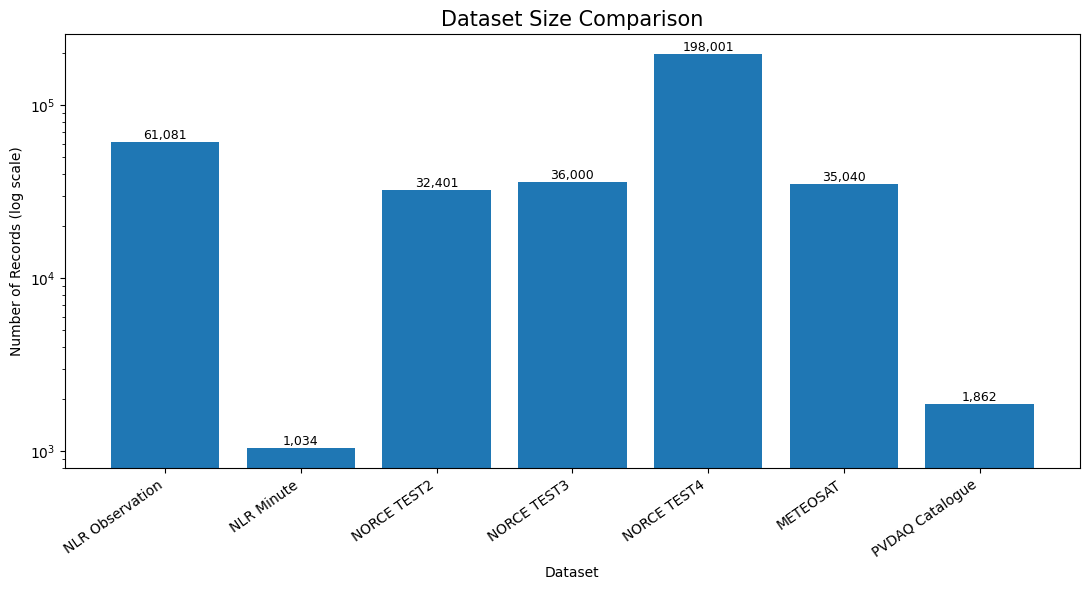

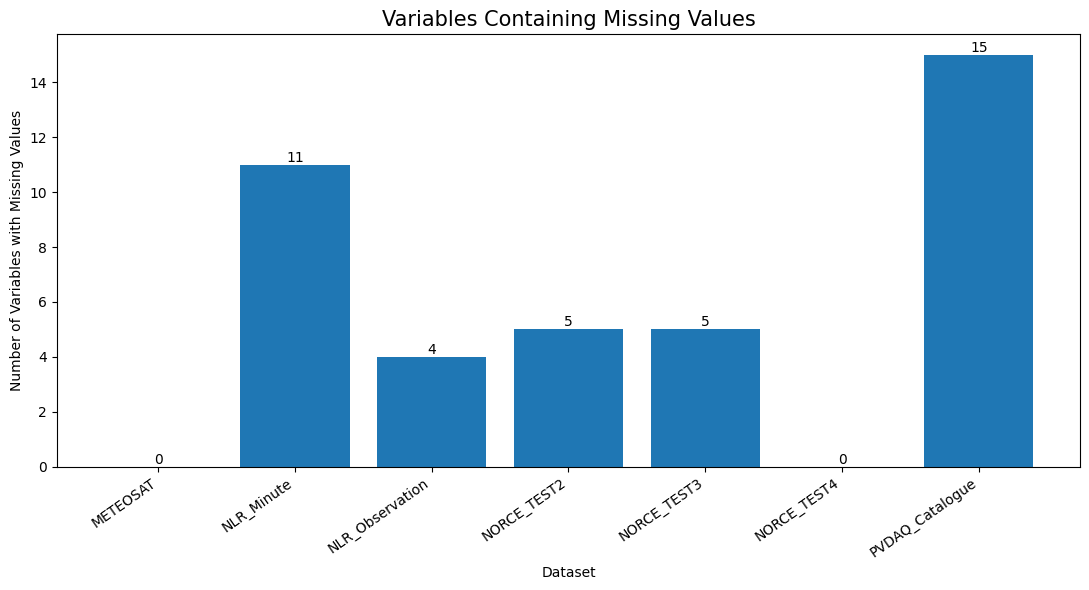

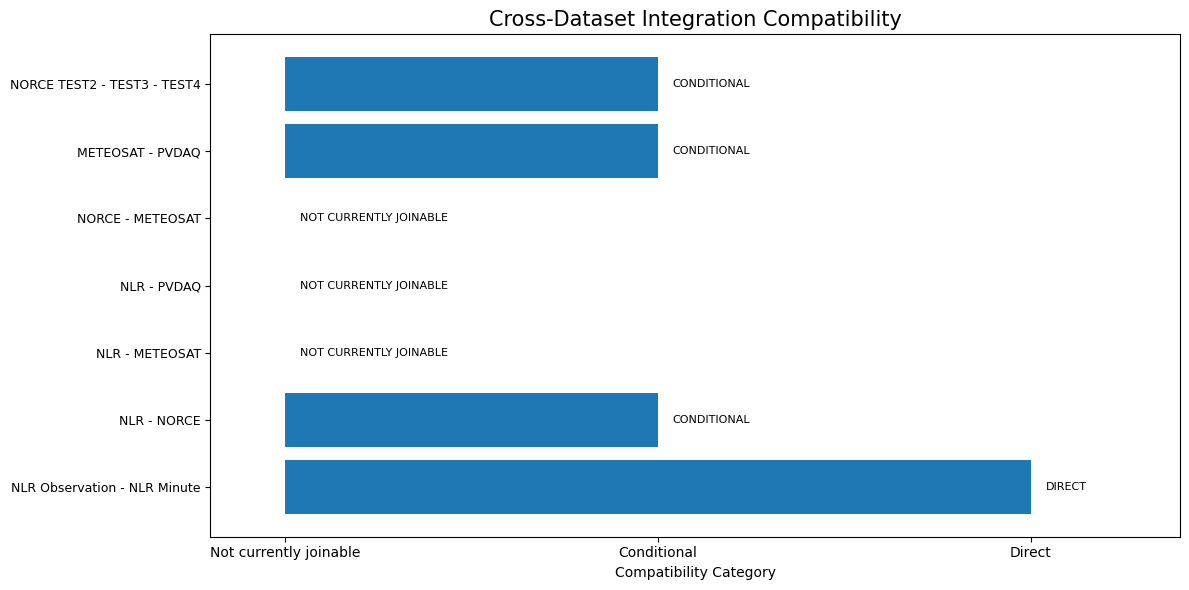

VISUALIZATION SUMMARY
------------------------------------------------------------

Dataset sizes:
NLR Observation: 61,081 records
NLR Minute: 1,034 records
NORCE TEST2: 32,401 records
NORCE TEST3: 36,000 records
NORCE TEST4: 198,001 records
METEOSAT: 35,040 records
PVDAQ Catalogue: 1,862 records

Missing-data summary:


,Dataset,Variables,Variables_With_Missing,Mean_Missing_Percentage
0,METEOSAT,14,0,0.000000
1,NLR_Minute,115,11,2.585965
2,NLR_Observation,44,4,2.936114
3,NORCE_TEST2,6,5,0.363500
4,NORCE_TEST3,6,5,0.722833
5,NORCE_TEST4,6,0,0.000000
6,PVDAQ_Catalogue,36,15,4.438083



Compatibility summary:


,Dataset_Pair,Compatibility
0,NLR Observation - NLR Minute,DIRECT
1,NLR - NORCE,CONDITIONAL
2,NLR - METEOSAT,NOT CURRENTLY JOINABLE
3,NLR - PVDAQ,NOT CURRENTLY JOINABLE
4,NORCE - METEOSAT,NOT CURRENTLY JOINABLE
5,METEOSAT - PVDAQ,CONDITIONAL
6,NORCE TEST2 - TEST3 - TEST4,CONDITIONAL



All three visualizations generated successfully.


In [ ]:

# ============================================================
# CROSS-DATASET ASSESSMENT — VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# 1. DATASET SIZE COMPARISON
# ------------------------------------------------------------

dataset_sizes = {
    "NLR Observation": len(df_nlr_observation),
    "NLR Minute": len(df_nlr_minute),
    "NORCE TEST2": len(df_norce_test2),
    "NORCE TEST3": len(df_norce_test3),
    "NORCE TEST4": len(df_norce_test4),
    "METEOSAT": len(df_meteosat),
    "PVDAQ Catalogue": len(df_pvdaq)
}

plt.figure(figsize=(11, 6))
bars = plt.bar(dataset_sizes.keys(), dataset_sizes.values())

plt.yscale("log")
plt.title("Dataset Size Comparison", fontsize=15)
plt.xlabel("Dataset")
plt.ylabel("Number of Records (log scale)")
plt.xticks(rotation=35, ha="right")

for bar, value in zip(bars, dataset_sizes.values()):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. MISSING-DATA COMPARISON
# ------------------------------------------------------------

missing_summary = (
    df_cross_inventory.groupby("Dataset")
    .agg(
        Variables=("Variable", "count"),
        Variables_With_Missing=(
            "Missing_Count",
            lambda x: (x > 0).sum()
        ),
        Mean_Missing_Percentage=("Missing_Percentage", "mean")
    )
    .reset_index()
)

plt.figure(figsize=(11, 6))

bars = plt.bar(
    missing_summary["Dataset"],
    missing_summary["Variables_With_Missing"]
)

plt.title("Variables Containing Missing Values", fontsize=15)
plt.xlabel("Dataset")
plt.ylabel("Number of Variables with Missing Values")
plt.xticks(rotation=35, ha="right")

for bar, value in zip(
    bars,
    missing_summary["Variables_With_Missing"]
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        str(value),
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 3. CROSS-DATASET COMPATIBILITY
# ------------------------------------------------------------

compatibility_encoding = {
    "NOT CURRENTLY JOINABLE": 0,
    "CONDITIONAL": 1,
    "DIRECT": 2
}

compatibility_values = (
    df_compatibility_matrix["Compatibility"]
    .map(compatibility_encoding)
)

plt.figure(figsize=(12, 6))

bars = plt.barh(
    df_compatibility_matrix["Dataset_Pair"],
    compatibility_values
)

plt.yticks(fontsize=9)
plt.xticks(
    [0, 1, 2],
    ["Not currently joinable", "Conditional", "Direct"]
)

plt.xlim(-0.2, 2.4)
plt.title("Cross-Dataset Integration Compatibility", fontsize=15)
plt.xlabel("Compatibility Category")

for bar, label in zip(
    bars,
    df_compatibility_matrix["Compatibility"]
):
    plt.text(
        bar.get_width() + 0.04,
        bar.get_y() + bar.get_height() / 2,
        label,
        va="center",
        fontsize=8
    )

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# SUMMARY
# ------------------------------------------------------------

print("VISUALIZATION SUMMARY")
print("-" * 60)

print("\nDataset sizes:")
for name, size in dataset_sizes.items():
    print(f"{name}: {size:,} records")

print("\nMissing-data summary:")
display(missing_summary)

print("\nCompatibility summary:")
display(
    df_compatibility_matrix[
        ["Dataset_Pair", "Compatibility"]
    ]
)

print("\nAll three visualizations generated successfully.")


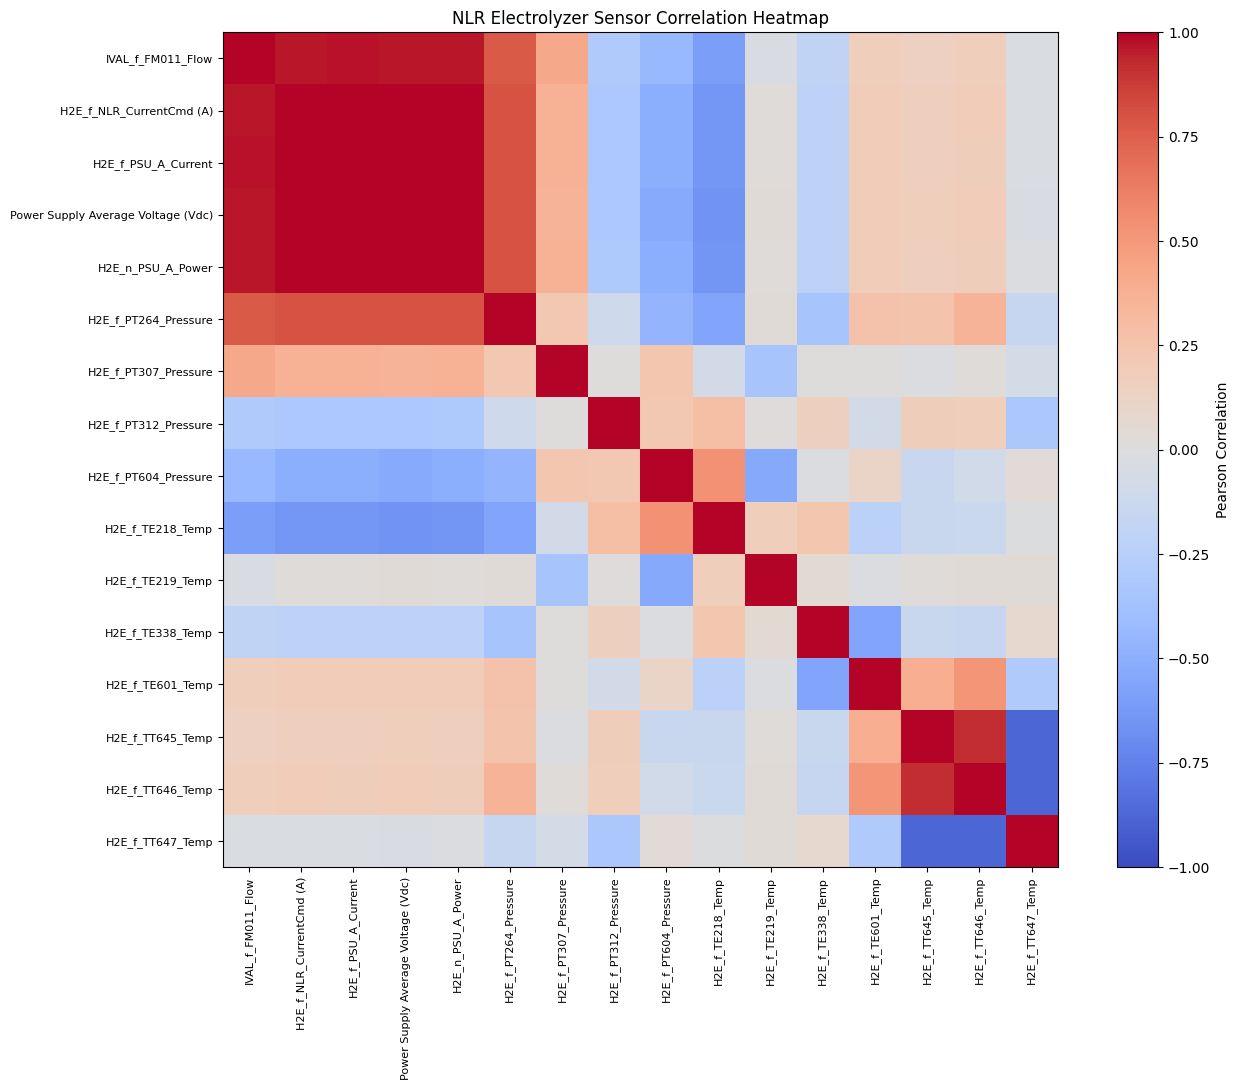

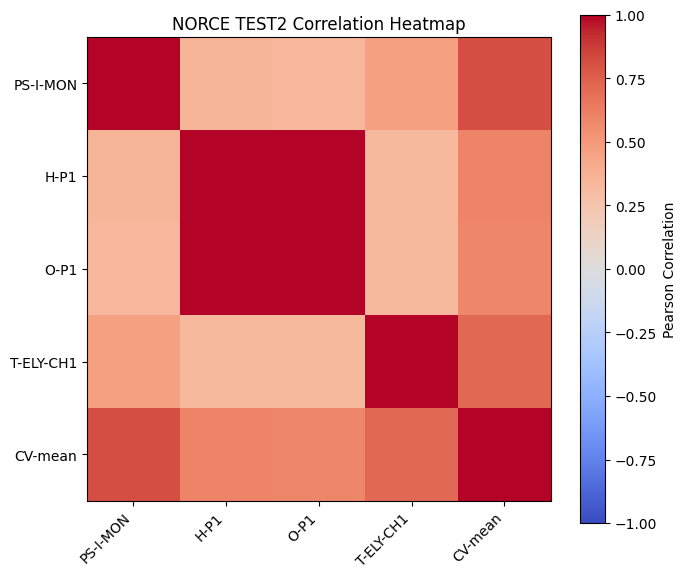

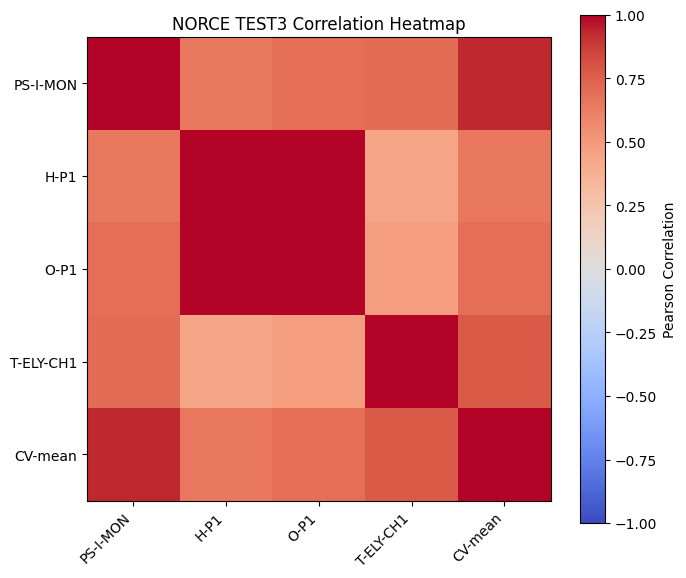

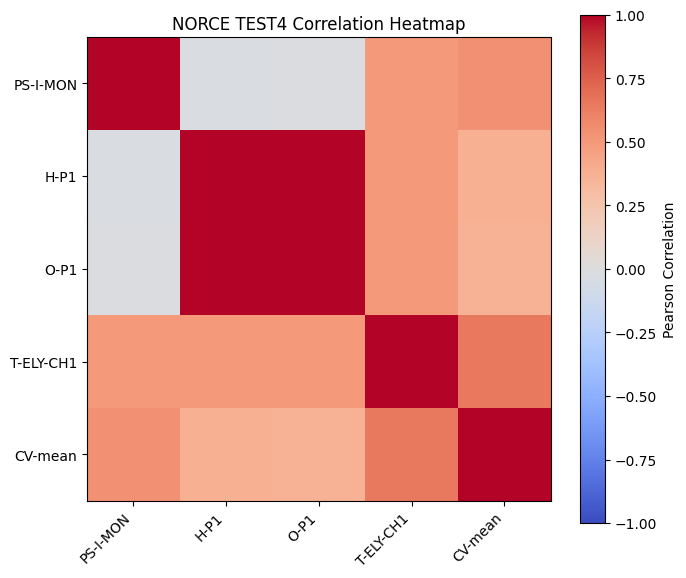

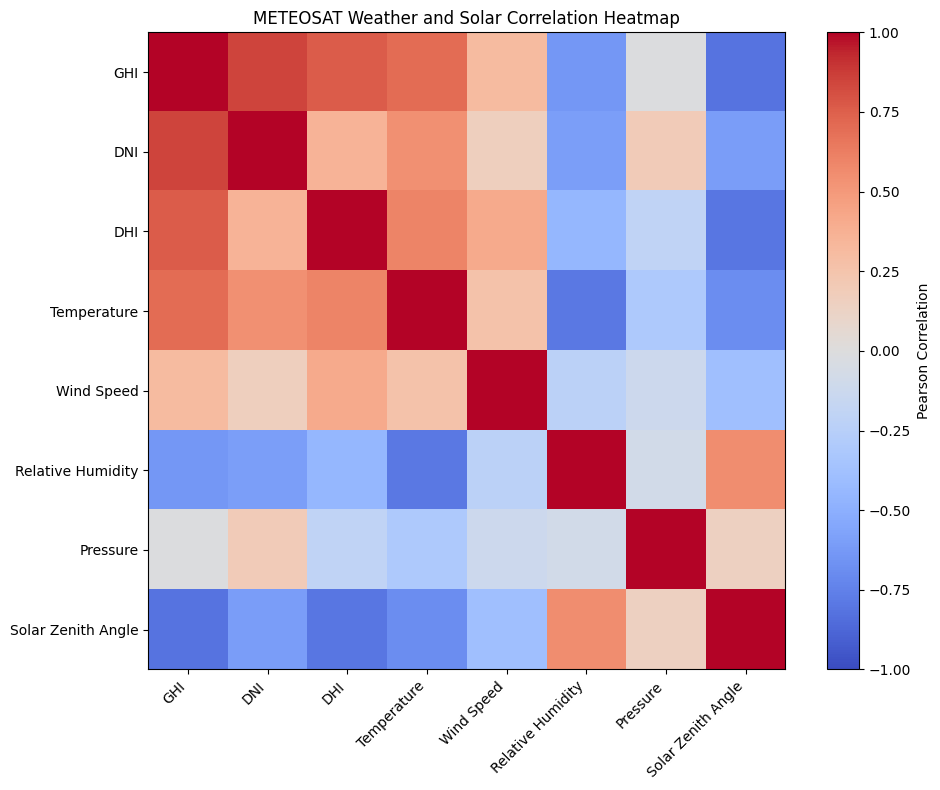

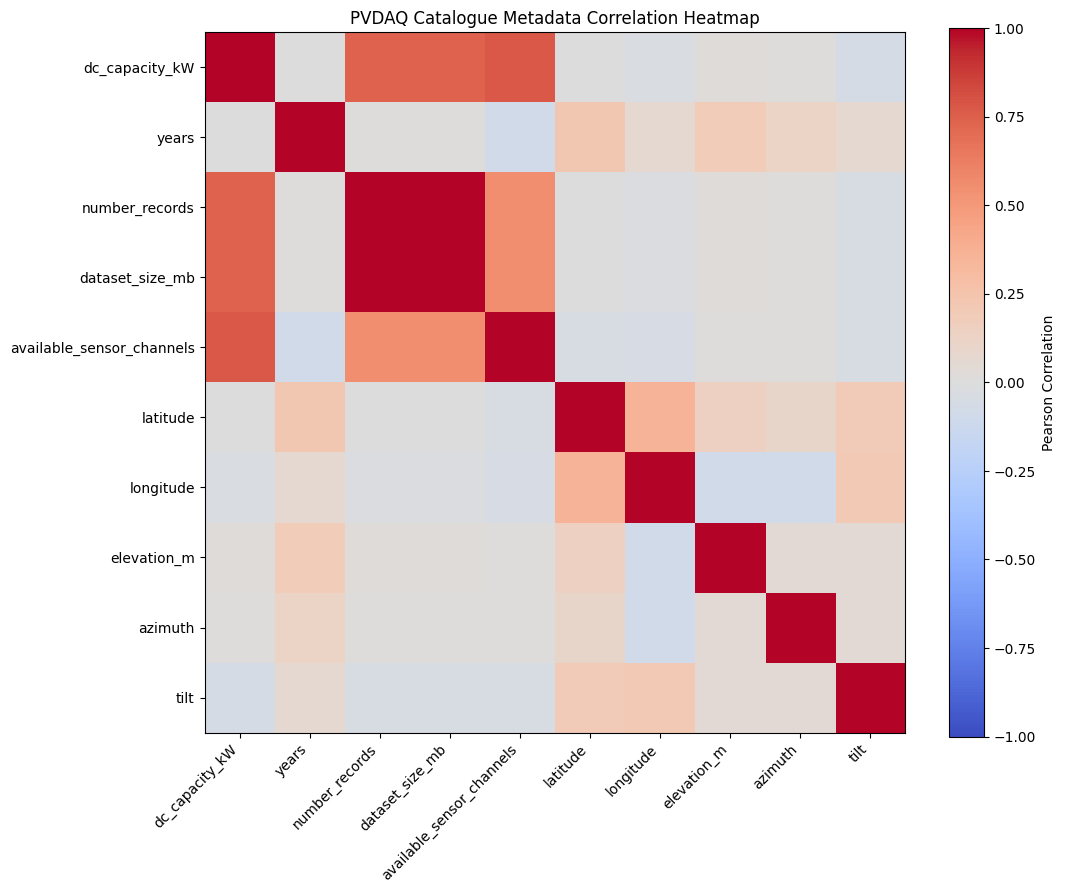


NLR CORRELATION MATRIX


,IVAL_f_FM011_Flow,H2E_f_NLR_CurrentCmd (A),H2E_f_PSU_A_Current,Power Supply Average Voltage (Vdc),H2E_n_PSU_A_Power,H2E_f_PT264_Pressure,H2E_f_PT307_Pressure,H2E_f_PT312_Pressure,H2E_f_PT604_Pressure,H2E_f_TE218_Temp,H2E_f_TE219_Temp,H2E_f_TE338_Temp,H2E_f_TE601_Temp,H2E_f_TT645_Temp,H2E_f_TT646_Temp,H2E_f_TT647_Temp
IVAL_f_FM011_Flow,1.000,0.962,0.970,0.967,0.969,0.773,0.419,-0.298,-0.437,-0.596,-0.033,-0.202,0.168,0.147,0.168,-0.025
H2E_f_NLR_CurrentCmd (A),0.962,1.000,0.997,0.996,0.995,0.798,0.361,-0.316,-0.507,-0.638,0.017,-0.213,0.181,0.164,0.181,-0.025
H2E_f_PSU_A_Current,0.970,0.997,1.000,0.999,0.998,0.799,0.363,-0.316,-0.507,-0.637,0.020,-0.214,0.182,0.163,0.179,-0.024
Power Supply Average Voltage (Vdc),0.967,0.996,0.999,1.000,0.995,0.799,0.355,-0.318,-0.525,-0.654,0.026,-0.213,0.183,0.170,0.186,-0.033
H2E_n_PSU_A_Power,0.969,0.995,0.998,0.995,1.000,0.802,0.360,-0.311,-0.507,-0.643,0.022,-0.218,0.187,0.159,0.176,-0.016
H2E_f_PT264_Pressure,0.773,0.798,0.799,0.799,0.802,1.000,0.214,-0.102,-0.453,-0.556,0.028,-0.348,0.264,0.251,0.356,-0.150
H2E_f_PT307_Pressure,0.419,0.361,0.363,0.355,0.360,0.214,1.000,0.002,0.234,-0.074,-0.349,0.004,0.006,-0.022,0.023,-0.064
H2E_f_PT312_Pressure,-0.298,-0.316,-0.316,-0.318,-0.311,-0.102,0.002,1.000,0.213,0.289,0.009,0.153,-0.071,0.178,0.167,-0.327
H2E_f_PT604_Pressure,-0.437,-0.507,-0.507,-0.525,-0.507,-0.453,0.234,0.213,1.000,0.537,-0.539,-0.019,0.116,-0.133,-0.084,0.036
H2E_f_TE218_Temp,-0.596,-0.638,-0.637,-0.654,-0.643,-0.556,-0.074,0.289,0.537,1.000,0.169,0.233,-0.231,-0.134,-0.129,-0.013



NORCE TEST2 CORRELATION MATRIX


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
PS-I-MON,1.000,0.348,0.336,0.462,0.812
H-P1,0.348,1.000,0.992,0.325,0.600
O-P1,0.336,0.992,1.000,0.321,0.591
T-ELY-CH1,0.462,0.325,0.321,1.000,0.711
CV-mean,0.812,0.600,0.591,0.711,1.000



NORCE TEST3 CORRELATION MATRIX


,PS-I-MON,H-P1,O-P1,T-ELY-CH1,CV-mean
PS-I-MON,1.000,0.648,0.690,0.701,0.931
H-P1,0.648,1.000,0.993,0.444,0.653
O-P1,0.690,0.993,1.000,0.474,0.689
T-ELY-CH1,0.701,0.444,0.474,1.000,0.768
CV-mean,0.931,0.653,0.689,0.768,1.000


... (3 outputs left out)

,GHI,DNI,DHI,Temperature,Wind Speed,Relative Humidity,Pressure,Solar Zenith Angle
GHI,1.000,0.845,0.758,0.702,0.312,-0.638,-0.008,-0.817
DNI,0.845,1.000,0.359,0.540,0.157,-0.600,0.190,-0.602
DHI,0.758,0.359,1.000,0.596,0.409,-0.448,-0.201,-0.799
Temperature,0.702,0.540,0.596,1.000,0.262,-0.790,-0.308,-0.695
Wind Speed,0.312,0.157,0.409,0.262,1.000,-0.231,-0.120,-0.390
Relative Humidity,-0.638,-0.600,-0.448,-0.790,-0.231,1.000,-0.082,0.561
Pressure,-0.008,0.190,-0.201,-0.308,-0.120,-0.082,1.000,0.142
Solar Zenith Angle,-0.817,-0.602,-0.799,-0.695,-0.390,0.561,0.142,1.000



PVDAQ CATALOGUE CORRELATION MATRIX


,dc_capacity_kW,years,number_records,dataset_size_mb,available_sensor_channels,latitude,longitude,elevation_m,azimuth,tilt
dc_capacity_kW,1.000,-0.001,0.741,0.741,0.774,-0.004,-0.027,0.017,0.002,-0.057
years,-0.001,1.000,0.001,0.001,-0.080,0.219,0.055,0.186,0.122,0.063
number_records,0.741,0.001,1.000,1.000,0.553,-0.002,-0.022,0.016,0.003,-0.041
dataset_size_mb,0.741,0.001,1.000,1.000,0.553,-0.002,-0.022,0.016,0.003,-0.041
available_sensor_channels,0.774,-0.080,0.553,0.553,1.000,-0.047,-0.054,0.005,0.003,-0.044
latitude,-0.004,0.219,-0.002,-0.002,-0.047,1.000,0.356,0.147,0.101,0.189
longitude,-0.027,0.055,-0.022,-0.022,-0.054,0.356,1.000,-0.087,-0.094,0.210
elevation_m,0.017,0.186,0.016,0.016,0.005,0.147,-0.087,1.000,0.039,0.047
azimuth,0.002,0.122,0.003,0.003,0.003,0.101,-0.094,0.039,1.000,0.043
tilt,-0.057,0.063,-0.041,-0.041,-0.044,0.189,0.210,0.047,0.043,1.000



ALL CORRELATION HEATMAPS GENERATED


In [ ]:

# ============================================================
# CROSS-DATASET CORRELATION ANALYSIS AND HEATMAPS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# 1. NLR — ELECTROLYZER SENSOR CORRELATION
# ------------------------------------------------------------

nlr_corr_features = [
    "IVAL_f_FM011_Flow",
    "H2E_f_NLR_CurrentCmd (A)",
    "H2E_f_PSU_A_Current",
    "Power Supply Average Voltage (Vdc)",
    "H2E_n_PSU_A_Power",
    "H2E_f_PT264_Pressure",
    "H2E_f_PT307_Pressure",
    "H2E_f_PT312_Pressure",
    "H2E_f_PT604_Pressure",
    "H2E_f_TE218_Temp",
    "H2E_f_TE219_Temp",
    "H2E_f_TE338_Temp",
    "H2E_f_TE601_Temp",
    "H2E_f_TT645_Temp",
    "H2E_f_TT646_Temp",
    "H2E_f_TT647_Temp"
]

nlr_corr_features = [
    col for col in nlr_corr_features
    if col in df_nlr_observation.columns
]

nlr_corr = df_nlr_observation[
    nlr_corr_features
].corr(method="pearson")

plt.figure(figsize=(14, 11))
plt.imshow(nlr_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson Correlation")
plt.xticks(
    range(len(nlr_corr.columns)),
    nlr_corr.columns,
    rotation=90,
    fontsize=8
)
plt.yticks(
    range(len(nlr_corr.index)),
    nlr_corr.index,
    fontsize=8
)
plt.title("NLR Electrolyzer Sensor Correlation Heatmap")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 2. NORCE — SEPARATE CORRELATION HEATMAPS
# ------------------------------------------------------------

norce_datasets = {
    "TEST2": df_norce_test2,
    "TEST3": df_norce_test3,
    "TEST4": df_norce_test4
}

norce_features = [
    "PS-I-MON",
    "H-P1",
    "O-P1",
    "T-ELY-CH1",
    "CV-mean"
]

norce_correlations = {}

for name, dataframe in norce_datasets.items():

    corr = dataframe[norce_features].corr(method="pearson")
    norce_correlations[name] = corr

    plt.figure(figsize=(7, 6))
    plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
    plt.colorbar(label="Pearson Correlation")

    plt.xticks(
        range(len(norce_features)),
        norce_features,
        rotation=45,
        ha="right"
    )
    plt.yticks(range(len(norce_features)), norce_features)

    plt.title(f"NORCE {name} Correlation Heatmap")
    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 3. METEOSAT — WEATHER AND SOLAR CORRELATION
# ------------------------------------------------------------

meteosat_corr_features = [
    "GHI",
    "DNI",
    "DHI",
    "Temperature",
    "Wind Speed",
    "Relative Humidity",
    "Pressure",
    "Solar Zenith Angle"
]

meteosat_corr = df_meteosat[
    meteosat_corr_features
].corr(method="pearson")

plt.figure(figsize=(10, 8))
plt.imshow(meteosat_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(meteosat_corr_features)),
    meteosat_corr_features,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(meteosat_corr_features)),
    meteosat_corr_features
)

plt.title("METEOSAT Weather and Solar Correlation Heatmap")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 4. PVDAQ — NUMERICAL CATALOGUE METADATA CORRELATION
# ------------------------------------------------------------

pvdaq_corr_features = [
    "dc_capacity_kW",
    "years",
    "number_records",
    "dataset_size_mb",
    "available_sensor_channels",
    "latitude",
    "longitude",
    "elevation_m",
    "azimuth",
    "tilt"
]

pvdaq_corr_features = [
    col for col in pvdaq_corr_features
    if col in df_pvdaq.columns
]

pvdaq_corr = df_pvdaq[
    pvdaq_corr_features
].corr(method="pearson")

plt.figure(figsize=(11, 9))
plt.imshow(pvdaq_corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Pearson Correlation")

plt.xticks(
    range(len(pvdaq_corr_features)),
    pvdaq_corr_features,
    rotation=45,
    ha="right"
)
plt.yticks(
    range(len(pvdaq_corr_features)),
    pvdaq_corr_features
)

plt.title("PVDAQ Catalogue Metadata Correlation Heatmap")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 5. DISPLAY CORRELATION TABLES
# ------------------------------------------------------------

print("\nNLR CORRELATION MATRIX")
display(nlr_corr.round(3))

for name, corr in norce_correlations.items():
    print(f"\nNORCE {name} CORRELATION MATRIX")
    display(corr.round(3))

print("\nMETEOSAT CORRELATION MATRIX")
display(meteosat_corr.round(3))

print("\nPVDAQ CATALOGUE CORRELATION MATRIX")
display(pvdaq_corr.round(3))

print("\nALL CORRELATION HEATMAPS GENERATED")


NLR EXPERIMENT-WISE CORRELATIONS


Feature,H2E_f_PSU_A_Current,H2E_f_PT264_Pressure,Power Supply Average Voltage (Vdc)
Experiment,,,
characterization_200.csv,0.998,0.988,0.998
windIEA3.4-5ms-A_2-200.csv,0.963,0.935,0.959
windIEA3.4-5ms-A_2-400.csv,0.963,0.949,0.958
windIEA3.4-5ms-C_2-200.csv,0.955,0.893,0.950
windIEA3.4-5ms-C_2-400.csv,0.958,0.932,0.953
windIEA3.4-7ms-A_1-200.csv,0.945,0.935,0.940
windIEA3.4-7ms-A_1-400.csv,0.946,0.940,0.941
windIEA3.4-7ms-C_1-200.csv,0.939,0.909,0.933
windIEA3.4-7ms-C_1-400.csv,0.930,0.944,0.924



VALID OBSERVATIONS PER EXPERIMENT


Feature,H2E_f_PSU_A_Current,H2E_f_PT264_Pressure,Power Supply Average Voltage (Vdc)
Experiment,,,
characterization_200.csv,17828,17828,17828
windIEA3.4-5ms-A_2-200.csv,3652,3652,3652
windIEA3.4-5ms-A_2-400.csv,3652,3652,3652
windIEA3.4-5ms-C_2-200.csv,3652,3652,3652
windIEA3.4-5ms-C_2-400.csv,3652,3652,3652
windIEA3.4-7ms-A_1-200.csv,3591,3591,3591
windIEA3.4-7ms-A_1-400.csv,3591,3591,3591
windIEA3.4-7ms-C_1-200.csv,3591,3591,3591
windIEA3.4-7ms-C_1-400.csv,3591,3591,3591


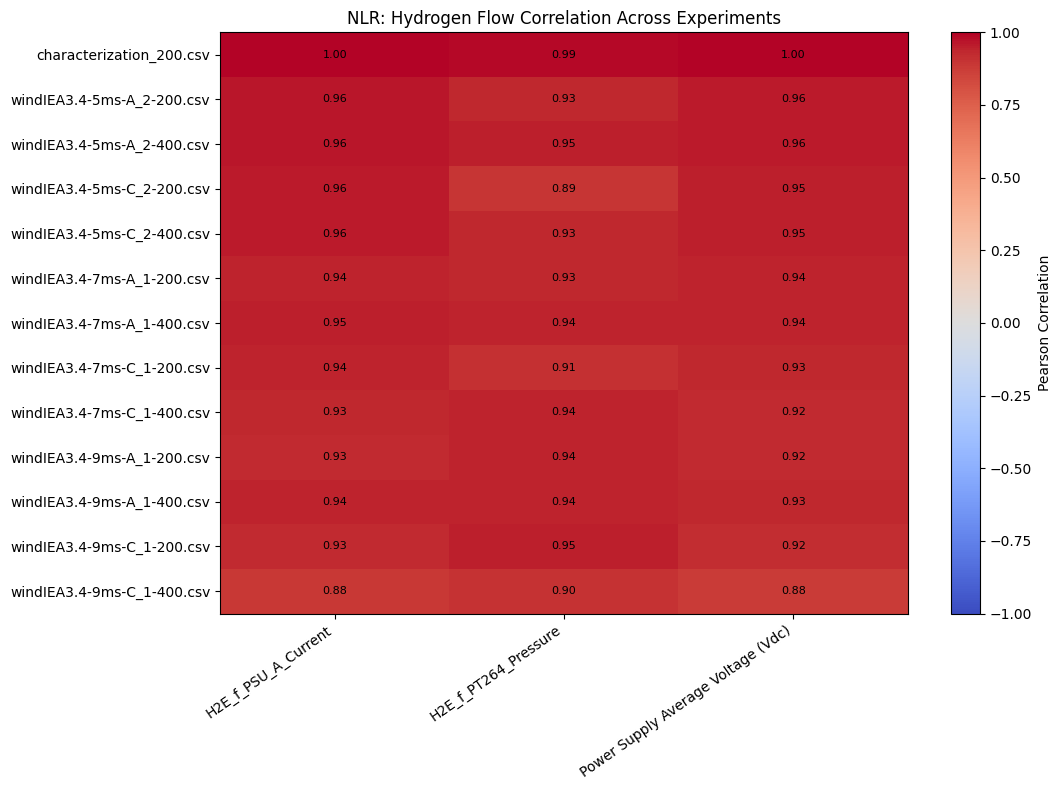


EXPERIMENT-WISE CORRELATION ANALYSIS COMPLETE


In [ ]:

# ============================================================
# NLR — EXPERIMENT-WISE CORRELATION ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

target = "IVAL_f_FM011_Flow"

features = [
    "H2E_f_PSU_A_Current",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PT264_Pressure"
]

required_columns = ["Experiment", target] + features

# Work on a copy; preserve original data
nlr_corr_work = df_nlr_observation[
    required_columns
].copy()

# Numeric conversion for analysis only
for col in [target] + features:
    nlr_corr_work[col] = pd.to_numeric(
        nlr_corr_work[col],
        errors="coerce"
    )

results = []

for experiment, group in nlr_corr_work.groupby(
    "Experiment",
    dropna=False
):
    for feature in features:

        valid = group[[target, feature]].dropna()

        correlation = (
            valid[target].corr(valid[feature])
            if len(valid) >= 3
            else np.nan
        )

        results.append({
            "Experiment": str(experiment),
            "Feature": feature,
            "Correlation": correlation,
            "Valid_Observations": len(valid)
        })

df_nlr_experiment_corr = pd.DataFrame(results)

print("=" * 90)
print("NLR EXPERIMENT-WISE CORRELATIONS")
print("=" * 90)

display(
    df_nlr_experiment_corr.pivot(
        index="Experiment",
        columns="Feature",
        values="Correlation"
    ).round(3)
)

print("\nVALID OBSERVATIONS PER EXPERIMENT")
display(
    df_nlr_experiment_corr.pivot(
        index="Experiment",
        columns="Feature",
        values="Valid_Observations"
    )
)

# ------------------------------------------------------------
# Heatmap of experiment-wise correlations
# ------------------------------------------------------------

corr_pivot = df_nlr_experiment_corr.pivot(
    index="Experiment",
    columns="Feature",
    values="Correlation"
)

fig, ax = plt.subplots(figsize=(11, 8))

image = ax.imshow(
    corr_pivot.values,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    aspect="auto"
)

ax.set_xticks(range(len(corr_pivot.columns)))
ax.set_xticklabels(
    corr_pivot.columns,
    rotation=35,
    ha="right"
)

ax.set_yticks(range(len(corr_pivot.index)))
ax.set_yticklabels(corr_pivot.index)

ax.set_title(
    "NLR: Hydrogen Flow Correlation Across Experiments"
)

for i in range(corr_pivot.shape[0]):
    for j in range(corr_pivot.shape[1]):
        value = corr_pivot.iloc[i, j]

        if pd.notna(value):
            ax.text(
                j, i, f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=8
            )

fig.colorbar(
    image,
    ax=ax,
    label="Pearson Correlation"
)

plt.tight_layout()
plt.show()

print("\nEXPERIMENT-WISE CORRELATION ANALYSIS COMPLETE")


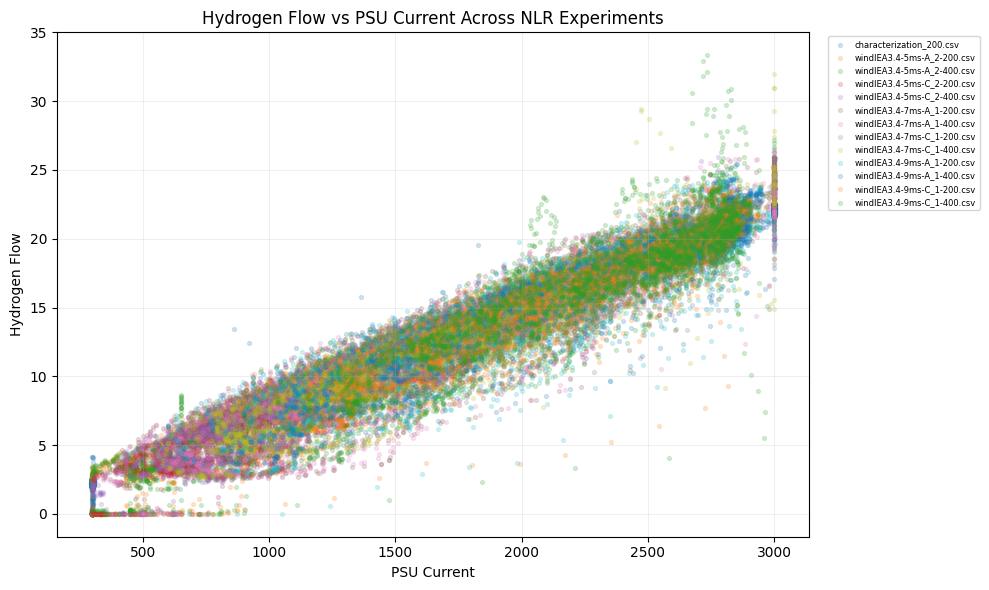

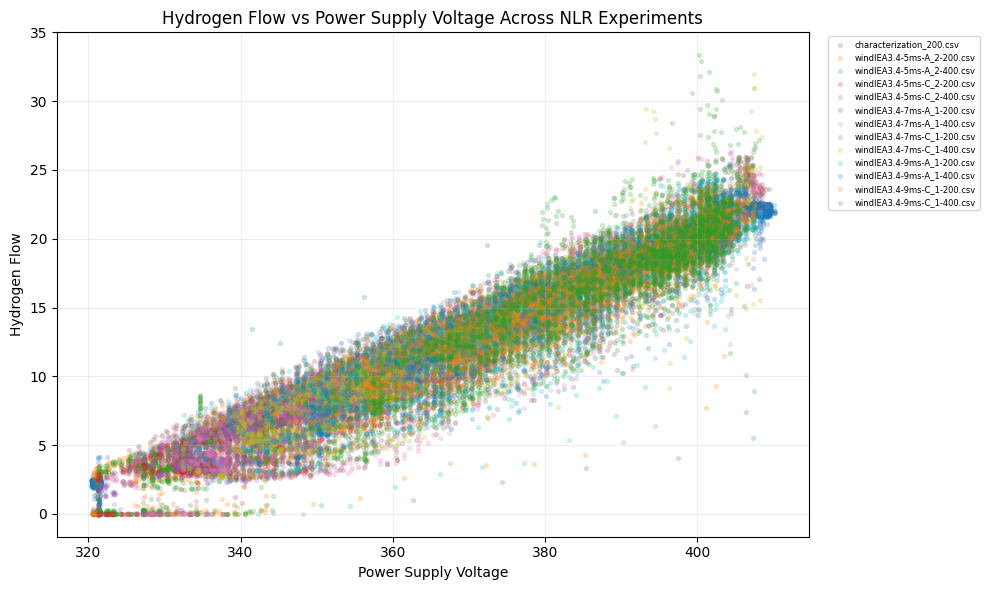

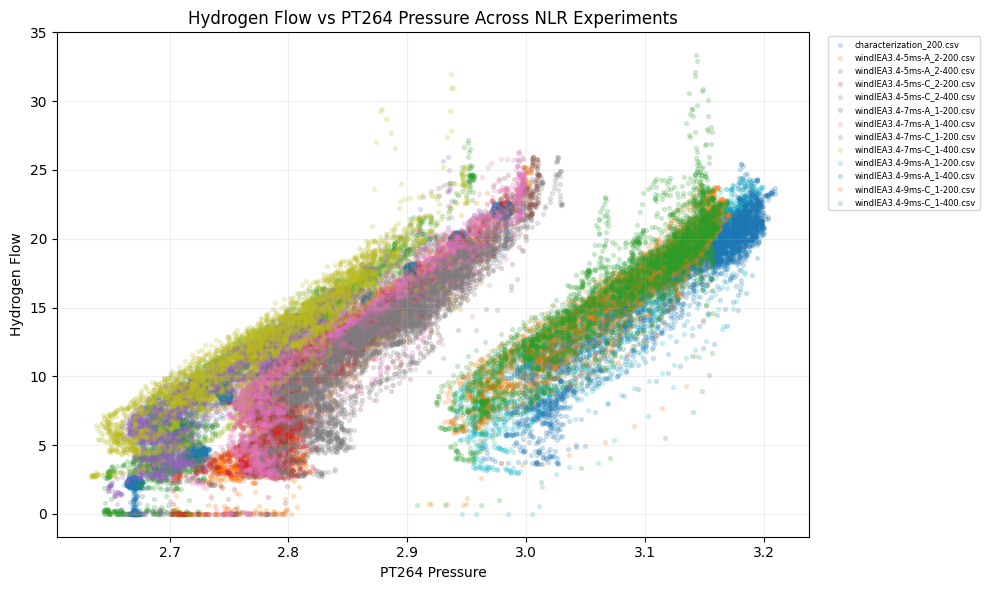

NLR SENSOR VS FLOW SCATTER PLOTS COMPLETE


In [ ]:

# ============================================================
# NLR — FLOW VS KEY SENSOR MEASUREMENTS
# ============================================================

import matplotlib.pyplot as plt
import pandas as pd

target = "IVAL_f_FM011_Flow"

plot_features = [
    "H2E_f_PSU_A_Current",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PT264_Pressure"
]

plot_labels = [
    "PSU Current",
    "Power Supply Voltage",
    "PT264 Pressure"
]

plot_data = df_nlr_observation[
    ["Experiment", target] + plot_features
].copy()

for col in [target] + plot_features:
    plot_data[col] = pd.to_numeric(
        plot_data[col],
        errors="coerce"
    )

for feature, label in zip(plot_features, plot_labels):

    plt.figure(figsize=(10, 6))

    for experiment, group in plot_data.groupby("Experiment"):

        valid = group[[target, feature]].dropna()

        plt.scatter(
            valid[feature],
            valid[target],
            alpha=0.18,
            s=8,
            label=experiment
        )

    plt.title(f"Hydrogen Flow vs {label} Across NLR Experiments")
    plt.xlabel(label)
    plt.ylabel("Hydrogen Flow")
    plt.grid(alpha=0.2)

    plt.legend(
        fontsize=6,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    plt.tight_layout()
    plt.show()

print("NLR SENSOR VS FLOW SCATTER PLOTS COMPLETE")


NORCE CV-MEAN SUMMARY


,Dataset,Valid_Count,Mean,Median,Std,Minimum,Maximum,Negative_Count
0,TEST2,32259,1.2679,1.5152,0.5309,0.4339,1.8658,0
1,TEST3,35689,1.4277,1.6981,0.6218,-0.0154,1.7874,3133
2,TEST4,198001,1.7124,1.7573,0.2766,-0.0401,1.8160,4568


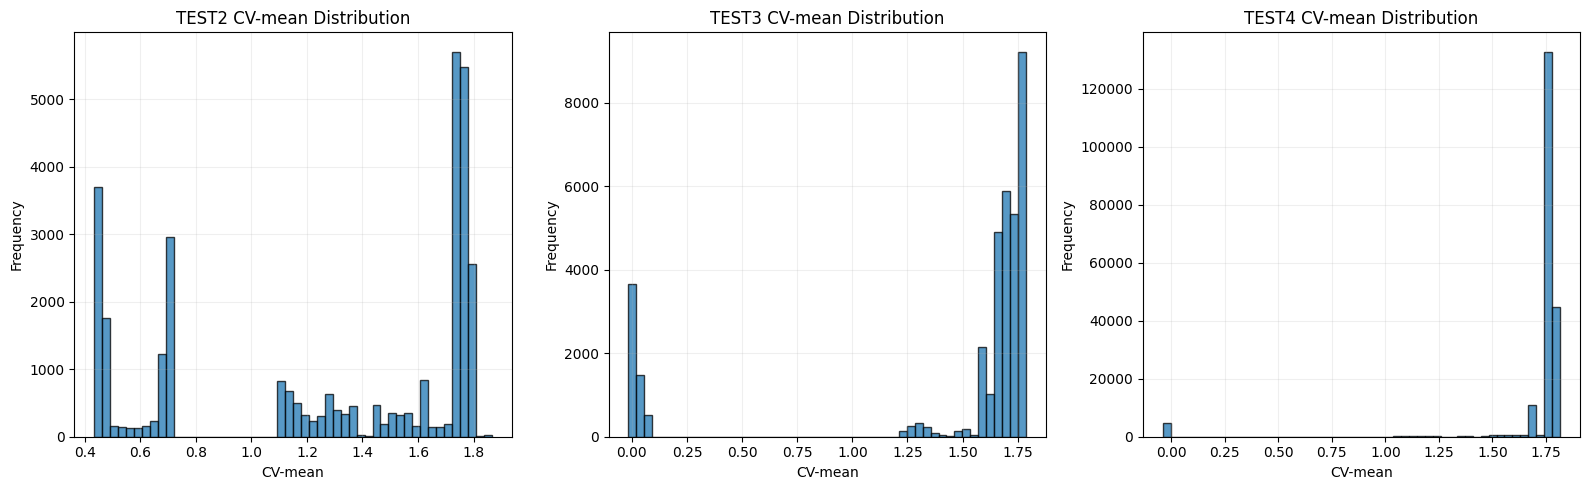

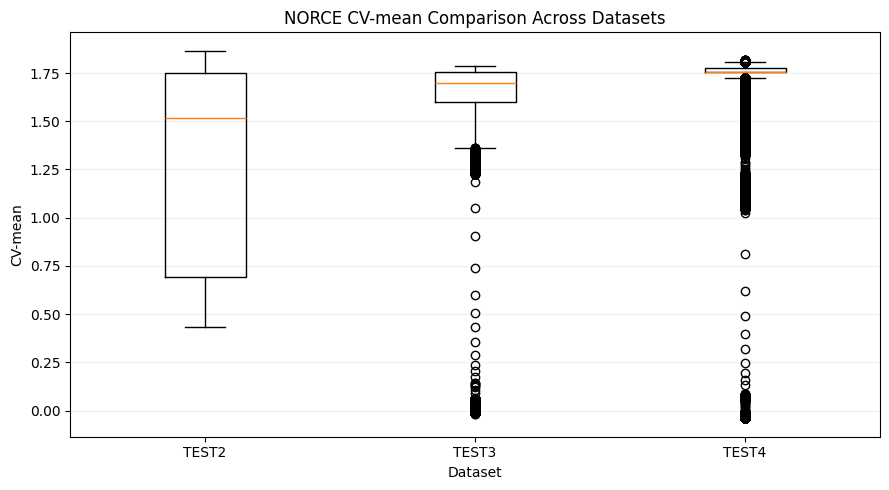

NORCE CV-MEAN DISTRIBUTION ANALYSIS COMPLETE


In [ ]:

# ============================================================
# NORCE — CV-MEAN DISTRIBUTION COMPARISON
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

norce_datasets = {
    "TEST2": df_norce_test2,
    "TEST3": df_norce_test3,
    "TEST4": df_norce_test4
}

target = "CV-mean"

# Summary statistics
summary = []

for name, df in norce_datasets.items():
    values = pd.to_numeric(df[target], errors="coerce").dropna()

    summary.append({
        "Dataset": name,
        "Valid_Count": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Std": values.std(),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "Negative_Count": (values < 0).sum()
    })

df_norce_cv_summary = pd.DataFrame(summary)

print("NORCE CV-MEAN SUMMARY")
display(df_norce_cv_summary.round(4))

# ------------------------------------------------------------
# 1. Individual distribution histograms
# ------------------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (name, df) in zip(axes, norce_datasets.items()):

    values = pd.to_numeric(df[target], errors="coerce").dropna()

    ax.hist(values, bins=50, edgecolor="black", alpha=0.75)
    ax.set_title(f"{name} CV-mean Distribution")
    ax.set_xlabel("CV-mean")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. Combined boxplot
# ------------------------------------------------------------

box_data = [
    pd.to_numeric(df[target], errors="coerce").dropna()
    for df in norce_datasets.values()
]

plt.figure(figsize=(9, 5))

plt.boxplot(
    box_data,
    tick_labels=list(norce_datasets.keys()),
    showfliers=True
)

plt.title("NORCE CV-mean Comparison Across Datasets")
plt.xlabel("Dataset")
plt.ylabel("CV-mean")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

print("NORCE CV-MEAN DISTRIBUTION ANALYSIS COMPLETE")


DAYTIME OBSERVATIONS: 17660

DAYTIME IRRADIANCE SUMMARY


,GHI,DNI,DHI
count,17660.000,17660.00,17660.000
mean,433.588,339.15,199.499
std,308.682,325.59,148.573
min,0.000,0.00,0.000
25%,143.000,34.00,85.000
50%,427.500,228.00,159.000
75%,684.000,657.00,309.000
max,1094.000,1031.00,527.000



DAYTIME IRRADIANCE CORRELATIONS


,GHI,DNI,DHI
GHI,1.000,0.749,0.533
DNI,0.749,1.000,-0.081
DHI,0.533,-0.081,1.000


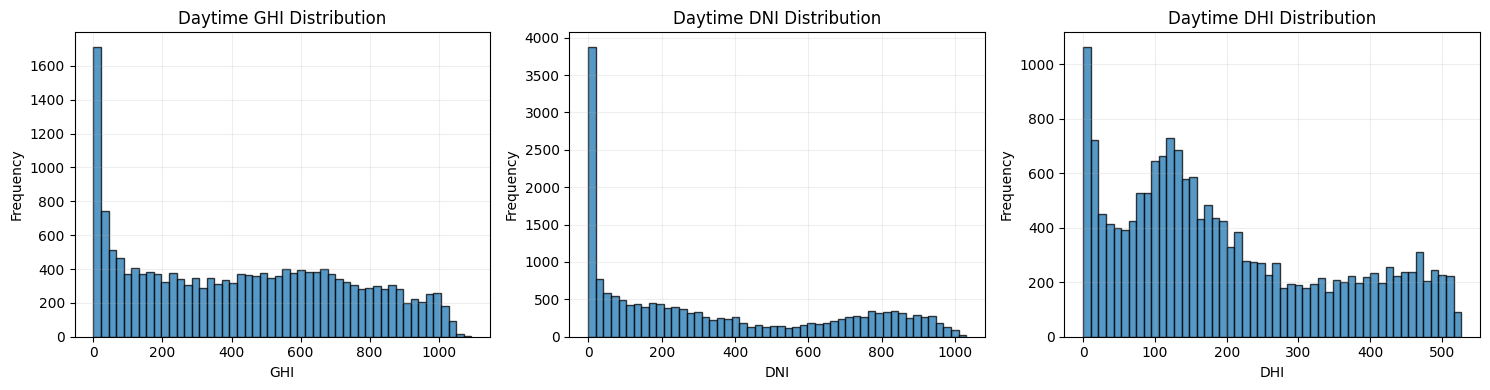

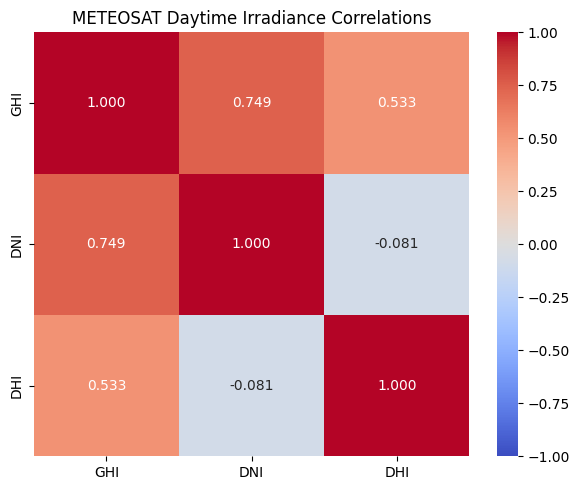


METEOSAT DAYTIME IRRADIANCE ANALYSIS COMPLETE


In [ ]:

# ============================================================
# METEOSAT — DAYTIME-ONLY IRRADIANCE ANALYSIS
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_day = df_meteosat[
    df_meteosat["Solar Zenith Angle"] < 90
].copy()

irradiance_columns = ["GHI", "DNI", "DHI"]

print("DAYTIME OBSERVATIONS:", len(df_day))

print("\nDAYTIME IRRADIANCE SUMMARY")
display(
    df_day[irradiance_columns]
    .describe()
    .round(3)
)

print("\nDAYTIME IRRADIANCE CORRELATIONS")
display(
    df_day[irradiance_columns]
    .corr()
    .round(3)
)

# Daytime irradiance distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, column in zip(axes, irradiance_columns):
    ax.hist(
        df_day[column].dropna(),
        bins=50,
        edgecolor="black",
        alpha=0.75
    )
    ax.set_title(f"Daytime {column} Distribution")
    ax.set_xlabel(column)
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

# Daytime irradiance correlation heatmap
plt.figure(figsize=(6, 5))

sns.heatmap(
    df_day[irradiance_columns].corr(),
    annot=True,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    fmt=".3f"
)

plt.title("METEOSAT Daytime Irradiance Correlations")
plt.tight_layout()
plt.show()

print("\nMETEOSAT DAYTIME IRRADIANCE ANALYSIS COMPLETE")


In [ ]:
# ============================================================
# STEP 8 — FINAL INTEGRATION READINESS REGISTER
# ============================================================

integration_readiness = [
    {
        "Dataset": "NLR",
        "Primary_Role": "Hydrogen electrolyzer operational modelling",
        "Temporal_Readiness": "READY",
        "Spatial_Readiness": "LOCATION UNVERIFIED",
        "Measurement_Readiness": "READY WITH FEATURE RESTRICTIONS",
        "Integration_Decision": "PRIMARY MODELLING DATASET",
        "Outstanding_Requirements": "Confirm physical units and retain experiment-aware validation"
    },
    {
        "Dataset": "NORCE",
        "Primary_Role": "Additional electrolyzer research measurements",
        "Temporal_Readiness": "NOT VERIFIED",
        "Spatial_Readiness": "NOT VERIFIED",
        "Measurement_Readiness": "PARTIAL",
        "Integration_Decision": "KEEP SEPARATE",
        "Outstanding_Requirements": "Obtain variable definitions, units, timestamps and experiment metadata"
    },
    {
        "Dataset": "METEOSAT",
        "Primary_Role": "Historical solar and weather context",
        "Temporal_Readiness": "READY INTERNALLY",
        "Spatial_Readiness": "BENGALURU VERIFIED",
        "Measurement_Readiness": "READY WITH LEAKAGE RESTRICTIONS",
        "Integration_Decision": "KEEP SEPARATE",
        "Outstanding_Requirements": "Obtain overlapping weather data for the NLR period and verify site relevance"
    },
    {
        "Dataset": "PVDAQ",
        "Primary_Role": "PV system catalogue and discovery",
        "Temporal_Readiness": "CATALOGUE DATES ONLY",
        "Spatial_Readiness": "COORDINATES AVAILABLE",
        "Measurement_Readiness": "NO GENERATION TARGET",
        "Integration_Decision": "CATALOGUE REFERENCE ONLY",
        "Outstanding_Requirements": "Obtain actual PV measurement records and verify relevant site locations"
    }
]

df_integration_readiness = pd.DataFrame(integration_readiness)

print("=" * 100)
print("FINAL DATASET INTEGRATION READINESS")
print("=" * 100)

display(df_integration_readiness)

print("\nFINAL PROJECT DECISIONS")
print("1. NLR is the primary source for hydrogen operational modelling.")
print("2. NORCE remains a separate research dataset pending documentation.")
print("3. METEOSAT remains a separate historical weather dataset.")
print("4. PVDAQ remains a system catalogue, not a PV generation dataset.")
print("5. No unsupported cross-dataset joins will be performed.")

print("\n" + "=" * 100)
print("INTEGRATION READINESS REGISTER COMPLETE")
print("=" * 100)

FINAL DATASET INTEGRATION READINESS


,Dataset,Primary_Role,Temporal_Readiness,Spatial_Readiness,Measurement_Readiness,Integration_Decision,Outstanding_Requirements
0,NLR,Hydrogen electrolyzer operational modelling,READY,LOCATION UNVERIFIED,READY WITH FEATURE RESTRICTIONS,PRIMARY MODELLING DATASET,Confirm physical units and retain experiment-a...
1,NORCE,Additional electrolyzer research measurements,NOT VERIFIED,NOT VERIFIED,PARTIAL,KEEP SEPARATE,"Obtain variable definitions, units, timestamps..."
2,METEOSAT,Historical solar and weather context,READY INTERNALLY,BENGALURU VERIFIED,READY WITH LEAKAGE RESTRICTIONS,KEEP SEPARATE,Obtain overlapping weather data for the NLR pe...
3,PVDAQ,PV system catalogue and discovery,CATALOGUE DATES ONLY,COORDINATES AVAILABLE,NO GENERATION TARGET,CATALOGUE REFERENCE ONLY,Obtain actual PV measurement records and verif...



FINAL PROJECT DECISIONS
1. NLR is the primary source for hydrogen operational modelling.
2. NORCE remains a separate research dataset pending documentation.
3. METEOSAT remains a separate historical weather dataset.
4. PVDAQ remains a system catalogue, not a PV generation dataset.
5. No unsupported cross-dataset joins will be performed.

INTEGRATION READINESS REGISTER COMPLETE


In [ ]:

# ============================================================
# NOTEBOOK 5 — FINAL CROSS-DATASET REPORT AND EXPORT
# ============================================================

import os
import shutil
import zipfile
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# 1. Verify required Notebook 5 dataframes
# ------------------------------------------------------------

required_objects = [
    "df_cross_inventory",
    "df_nlr_observation",
    "df_nlr_minute",
    "df_norce_test2",
    "df_norce_test3",
    "df_norce_test4",
    "df_meteosat",
    "df_pvdaq"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        "Missing required objects: " + ", ".join(missing_objects)
    )

print("All required datasets and inventory are available.")

# ------------------------------------------------------------
# 2. Create final export directories
# ------------------------------------------------------------

export_root = "/content/HydrogenDigitalTwin_CrossDataset_Export"

if os.path.exists(export_root):
    shutil.rmtree(export_root)

report_dir = os.path.join(export_root, "cross_dataset_assessment")
os.makedirs(report_dir, exist_ok=True)

# Preserve all four extracted dataset packages
source_root = "/content/cross_dataset"
destination_root = os.path.join(export_root, "source_packages")

if os.path.exists(source_root):
    shutil.copytree(source_root, destination_root)

# ------------------------------------------------------------
# 3. Save variable inventory
# ------------------------------------------------------------

df_cross_inventory.to_csv(
    os.path.join(report_dir, "cross_dataset_variable_inventory.csv"),
    index=False
)

# ------------------------------------------------------------
# 4. Dataset overview
# ------------------------------------------------------------

dataset_frames = {
    "NLR_Observation": df_nlr_observation,
    "NLR_Minute": df_nlr_minute,
    "NORCE_TEST2": df_norce_test2,
    "NORCE_TEST3": df_norce_test3,
    "NORCE_TEST4": df_norce_test4,
    "METEOSAT": df_meteosat,
    "PVDAQ_Catalogue": df_pvdaq
}

overview = []

for name, df in dataset_frames.items():
    overview.append({
        "Dataset": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing_Cells": int(df.isna().sum().sum()),
        "Numeric_Columns": int(
            df.select_dtypes(include=np.number).shape[1]
        )
    })

df_overview = pd.DataFrame(overview)

df_overview.to_csv(
    os.path.join(report_dir, "cross_dataset_overview.csv"),
    index=False
)

# ------------------------------------------------------------
# 5. Compatibility matrix
# ------------------------------------------------------------

compatibility_rows = [
    {
        "Dataset_Pair": "NLR Observation - NLR Minute",
        "Status": "DIRECT",
        "Reason": "Same underlying NLR experiments and matching timestamps; different aggregation levels."
    },
    {
        "Dataset_Pair": "NLR - NORCE",
        "Status": "CONDITIONAL",
        "Reason": "Both concern electrolyzer operation, but NORCE timestamps, location and variable definitions are unverified."
    },
    {
        "Dataset_Pair": "NLR - METEOSAT",
        "Status": "NOT CURRENTLY JOINABLE",
        "Reason": "No calendar overlap: NLR is from 2025 and METEOSAT is from 2017. NLR location is unverified."
    },
    {
        "Dataset_Pair": "NLR - PVDAQ",
        "Status": "NOT CURRENTLY JOINABLE",
        "Reason": "PVDAQ is a system catalogue without measurement-level generation records."
    },
    {
        "Dataset_Pair": "NORCE - METEOSAT",
        "Status": "NOT CURRENTLY JOINABLE",
        "Reason": "NORCE temporal and spatial correspondence has not been established."
    },
    {
        "Dataset_Pair": "METEOSAT - PVDAQ",
        "Status": "CONDITIONAL",
        "Reason": "Requires a relevant PVDAQ site near Bengaluru and actual PV measurement data."
    },
    {
        "Dataset_Pair": "NORCE TEST2 - TEST3 - TEST4",
        "Status": "CONDITIONAL",
        "Reason": "Shared variable names, but experiment comparability and measurement definitions remain unverified."
    }
]

df_compatibility = pd.DataFrame(compatibility_rows)

df_compatibility.to_csv(
    os.path.join(report_dir, "cross_dataset_compatibility_matrix.csv"),
    index=False
)

# ------------------------------------------------------------
# 6. Save NLR experiment-wise correlations
# ------------------------------------------------------------

nlr_features = [
    "H2E_f_PSU_A_Current",
    "Power Supply Average Voltage (Vdc)",
    "H2E_f_PT264_Pressure"
]

nlr_target = "IVAL_f_FM011_Flow"

nlr_corr_rows = []

for experiment, group in df_nlr_observation.groupby("Experiment"):
    for feature in nlr_features:

        valid = group[[nlr_target, feature]].apply(
            pd.to_numeric, errors="coerce"
        ).dropna()

        nlr_corr_rows.append({
            "Experiment": experiment,
            "Feature": feature,
            "Correlation": (
                valid[nlr_target].corr(valid[feature])
                if len(valid) >= 3 else np.nan
            ),
            "Valid_Observations": len(valid)
        })

df_nlr_final_corr = pd.DataFrame(nlr_corr_rows)

df_nlr_final_corr.to_csv(
    os.path.join(report_dir, "nlr_experiment_wise_correlations.csv"),
    index=False
)

# ------------------------------------------------------------
# 7. Save NORCE CV-mean statistics and correlations
# ------------------------------------------------------------

norce_frames = {
    "TEST2": df_norce_test2,
    "TEST3": df_norce_test3,
    "TEST4": df_norce_test4
}

norce_summary = []
norce_correlations = []

for name, df in norce_frames.items():

    numeric_df = df.select_dtypes(include=np.number)

    values = pd.to_numeric(
        df["CV-mean"], errors="coerce"
    ).dropna()

    norce_summary.append({
        "Dataset": name,
        "Valid_CV_Count": len(values),
        "Mean": values.mean(),
        "Median": values.median(),
        "Standard_Deviation": values.std(),
        "Minimum": values.min(),
        "Maximum": values.max(),
        "Negative_Count": int((values < 0).sum())
    })

    corr = numeric_df.corr()

    for row_name in corr.index:
        for column_name in corr.columns:
            norce_correlations.append({
                "Dataset": name,
                "Variable_1": row_name,
                "Variable_2": column_name,
                "Pearson_Correlation": corr.loc[
                    row_name, column_name
                ]
            })

pd.DataFrame(norce_summary).to_csv(
    os.path.join(report_dir, "norce_cv_mean_distribution_summary.csv"),
    index=False
)

pd.DataFrame(norce_correlations).to_csv(
    os.path.join(report_dir, "norce_correlation_matrices_long.csv"),
    index=False
)

# ------------------------------------------------------------
# 8. Save METEOSAT daytime irradiance analysis
# ------------------------------------------------------------

df_day_final = df_meteosat[
    df_meteosat["Solar Zenith Angle"] < 90
].copy()

irradiance_columns = ["GHI", "DNI", "DHI"]

df_day_final[irradiance_columns].describe().to_csv(
    os.path.join(report_dir, "meteosat_daytime_irradiance_summary.csv")
)

df_day_final[irradiance_columns].corr().to_csv(
    os.path.join(report_dir, "meteosat_daytime_irradiance_correlations.csv")
)

# ------------------------------------------------------------
# 9. Save PVDAQ catalogue limitations and readiness summary
# ------------------------------------------------------------

pvdaq_summary = pd.DataFrame([
    {
        "Assessment": "Catalogue records",
        "Result": len(df_pvdaq),
        "Interpretation": "System catalogue records, not actual PV measurement observations."
    },
    {
        "Assessment": "Unique system IDs",
        "Result": df_pvdaq["system_id"].nunique(),
        "Interpretation": "Two system IDs are duplicated in the catalogue."
    },
    {
        "Assessment": "PV generation target available",
        "Result": "No",
        "Interpretation": "No verified power or energy generation target is present."
    },
    {
        "Assessment": "Measurement timestamps available",
        "Result": "No",
        "Interpretation": "Only first and last coverage timestamps are provided."
    }
])

pvdaq_summary.to_csv(
    os.path.join(report_dir, "pvdaq_catalogue_assessment.csv"),
    index=False
)

# ------------------------------------------------------------
# 10. Prepare consolidated scientific report
# ------------------------------------------------------------

report = """
HYDROGEN DIGITAL TWIN
CROSS-DATASET EDA AND INTEGRATION READINESS REPORT
==================================================

PURPOSE
-------
This report consolidates the exploratory data analysis and
cross-dataset compatibility assessment completed in Notebook 5.

No model training or cross-dataset merging was performed.

DATASETS
--------
1. NLR: Wind-powered PEM electrolyzer observations and minute-level
   aggregates from 13 experiments.
2. NORCE: TEST2, TEST3 and TEST4 electrolyzer research datasets.
3. METEOSAT: Bengaluru meteorological and solar irradiance data
   covering calendar year 2017 at 15-minute intervals.
4. PVDAQ: Photovoltaic system catalogue, not actual PV generation
   measurements.

NLR FINDINGS
------------
- NLR is the primary modelling dataset at this stage.
- Real-time hydrogen flow estimation is a candidate task.
- Future hydrogen flow forecasting is also a candidate task,
  subject to valid forecast-origin and lag construction.
- PSU current, supply voltage and PT264 pressure show strong
  positive experiment-wise correlations with hydrogen flow.
- Across all 13 experiments:
  PSU current correlation range: 0.883 to 0.998.
  Supply voltage correlation range: 0.878 to 0.998.
  PT264 pressure correlation range: 0.893 to 0.988.
- Scatter plots show strong electrical relationships and
  experiment-dependent pressure clusters.
- Highly correlated electrical features are retained provisionally.
- Experiment-aware validation is required.
- No exact 1 Hz sampling claim is justified because timestamps
  have minute-level precision.

NORCE FINDINGS
--------------
- TEST2, TEST3 and TEST4 have different CV-mean distributions.
- TEST2 has a broad, multimodal distribution.
- TEST3 and TEST4 have concentrated high-value regions and
  lower-value observations.
- CV-mean remains a potential target only.
- Physical meaning, units and calculation dependencies are
  unverified.
- No verified timestamps, sampling interval or experiment IDs.
- Keep all three datasets separate.
- Preserve missing values, repeated observations and negative
  measurements pending documentation.

METEOSAT FINDINGS
-----------------
- 35,040 observations cover 2017 at 15-minute intervals.
- 17,660 observations have Solar Zenith Angle below 90 degrees.
- Daytime mean irradiance:
  GHI: 433.588
  DNI: 339.150
  DHI: 199.499
- Daytime Pearson correlations:
  GHI-DNI: 0.749
  GHI-DHI: 0.533
  DNI-DHI: -0.081
- Nighttime zeros influence full-year pooled correlations.
- Contemporaneous DNI and DHI must not be used as future GHI
  predictors unless they are genuinely available at forecast origin.
- METEOSAT 2017 does not overlap NLR 2025.
- Keep METEOSAT separate pending overlapping weather observations
  and site relevance verification.

PVDAQ FINDINGS
--------------
- PVDAQ file is a system catalogue, not a generation time series.
- No verified PV power or energy target is available.
- No measurement-level timestamps or sampling interval.
- Catalogue may support future system discovery and metadata
  selection, but not PV generation model training in its current form.
- Extreme catalogue values and QA flags must be interpreted
  cautiously; do not automatically remove records.

CROSS-DATASET COMPATIBILITY
---------------------------
- NLR observation and NLR minute: DIRECT compatibility.
- NLR and NORCE: CONDITIONAL.
- NLR and METEOSAT: NOT CURRENTLY JOINABLE.
- NLR and PVDAQ: NOT CURRENTLY JOINABLE.
- NORCE and METEOSAT: NOT CURRENTLY JOINABLE.
- METEOSAT and PVDAQ: CONDITIONAL.
- NORCE TEST2/TEST3/TEST4: CONDITIONAL.

INTEGRATION READINESS
---------------------
NLR:
Primary modelling dataset. Verify physical units and retain
experiment identity for validation.

NORCE:
Keep separate until variable definitions, units, timestamps
and experiment metadata are obtained.

METEOSAT:
Keep separate. Obtain weather data overlapping the NLR period
and verify geographical relevance.

PVDAQ:
Catalogue reference only. Obtain actual measurement records
before considering PV generation modelling.

SCIENTIFIC AND DATA GOVERNANCE DECISIONS
----------------------------------------
- Original datasets remain preserved.
- No automatic outlier deletion.
- No unsupported missing-value interpolation.
- No unsupported sensor-unit conversions.
- No unverified temporal or spatial joins.
- No target leakage from contemporaneous or derived variables.
- No model training was performed during this assessment.

STATUS
------
Cross-dataset EDA, visual analysis and initial integration-readiness
assessment are documented. Dataset integration is not yet approved.
"""

report_path = os.path.join(
    report_dir,
    "HydrogenDigitalTwin_CrossDataset_EDA_Report.txt"
)

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

# ------------------------------------------------------------
# 11. Save package manifest
# ------------------------------------------------------------

manifest = []

for root, dirs, files in os.walk(export_root):
    for filename in files:
        full_path = os.path.join(root, filename)
        manifest.append({
            "Relative_Path": os.path.relpath(full_path, export_root),
            "Size_KB": round(os.path.getsize(full_path) / 1024, 2)
        })

pd.DataFrame(manifest).to_csv(
    os.path.join(report_dir, "export_manifest.csv"),
    index=False
)

# ------------------------------------------------------------
# 12. Create final ZIP
# ------------------------------------------------------------

zip_path = "/content/HydrogenDigitalTwin_CrossDataset_Final.zip"

if os.path.exists(zip_path):
    os.remove(zip_path)

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as archive:

    for root, dirs, files in os.walk(export_root):
        for filename in files:
            full_path = os.path.join(root, filename)
            archive_name = os.path.relpath(
                full_path, export_root
            )
            archive.write(full_path, archive_name)

# ------------------------------------------------------------
# 13. Final verification
# ------------------------------------------------------------

with zipfile.ZipFile(zip_path, "r") as archive:
    bad_file = archive.testzip()
    zip_contents = archive.namelist()

print("\n" + "=" * 65)
print("CROSS-DATASET EXPORT COMPLETE")
print("=" * 65)

print("Export directory:", export_root)
print("ZIP file:", zip_path)
print("ZIP size (MB):", round(os.path.getsize(zip_path) / (1024**2), 2))
print("Files in ZIP:", len(zip_contents))
print("ZIP integrity:", "PASSED" if bad_file is None else bad_file)

print("\nDATASET OVERVIEW")
display(df_overview)

print("\nCOMPATIBILITY MATRIX")
display(df_compatibility)

print("\nNLR EXPERIMENT-WISE CORRELATION RANGE")
display(
    df_nlr_final_corr.groupby("Feature")["Correlation"]
    .agg(["min", "max", "mean"])
    .round(3)
)

print("\nDownload the ZIP from the Colab Files panel:")
print(zip_path)


All required datasets and inventory are available.

CROSS-DATASET EXPORT COMPLETE
Export directory: /content/HydrogenDigitalTwin_CrossDataset_Export
ZIP file: /content/HydrogenDigitalTwin_CrossDataset_Final.zip
ZIP size (MB): 9.0
Files in ZIP: 30
ZIP integrity: PASSED

DATASET OVERVIEW


,Dataset,Rows,Columns,Missing_Cells,Numeric_Columns
0,NLR_Observation,61081,44,78910,38
1,NLR_Minute,1034,115,3075,111
2,NORCE_TEST2,32401,6,707,6
3,NORCE_TEST3,36000,6,1561,6
4,NORCE_TEST4,198001,6,0,6
5,METEOSAT,35040,14,0,13
6,PVDAQ_Catalogue,1862,36,2975,17



COMPATIBILITY MATRIX


,Dataset_Pair,Status,Reason
0,NLR Observation - NLR Minute,DIRECT,Same underlying NLR experiments and matching t...
1,NLR - NORCE,CONDITIONAL,"Both concern electrolyzer operation, but NORCE..."
2,NLR - METEOSAT,NOT CURRENTLY JOINABLE,No calendar overlap: NLR is from 2025 and METE...
3,NLR - PVDAQ,NOT CURRENTLY JOINABLE,PVDAQ is a system catalogue without measuremen...
4,NORCE - METEOSAT,NOT CURRENTLY JOINABLE,NORCE temporal and spatial correspondence has ...
5,METEOSAT - PVDAQ,CONDITIONAL,Requires a relevant PVDAQ site near Bengaluru ...
6,NORCE TEST2 - TEST3 - TEST4,CONDITIONAL,"Shared variable names, but experiment comparab..."



NLR EXPERIMENT-WISE CORRELATION RANGE


,min,max,mean
Feature,,,
H2E_f_PSU_A_Current,0.883,0.998,0.944
H2E_f_PT264_Pressure,0.893,0.988,0.936
Power Supply Average Voltage (Vdc),0.878,0.998,0.939



Download the ZIP from the Colab Files panel:
/content/HydrogenDigitalTwin_CrossDataset_Final.zip
